# TPC distortion corrections from the CM laser: what we learned
*(meeting version; every figure: two panels, South | North, unless noted)*

**The problem.** TPC electrons drift up to 1 m in E and B. Anything that bends the drift moves the measured cluster:
- **static distortions** (present without beam): field-cage voltages, module frames, the TPC tilt and position in the
  magnet (E×B);
- **space charge** (ions from the collisions and the GEM back-flow): grows with luminosity.

PHGarfield corrects each cluster by drifting it back through a model of E and B:

  static model + space-charge map × **keff**

**The tool.** The central-membrane (CM) laser releases electrons from a known stripe pattern at z = 0. They drift the
full length, so they measure the total distortion at every R and φ, run by run.

**What we want.** The map shape, keff (and how it scales with the GEM current), and the static parameters, so that
tracks come out unbiased.

**Data.** Beam runs 79508 / 79513 / 79516 / 79529 (low luminosity, about 2 µA per side) and 80892 / 81558 (about 6 µA),
in 17 blocks of 100 segments. No-beam field-on runs 75073 (before the IFC voltage change) and 83319 (after). Field-off
run 78242.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import bsnb as b, bsplots as bp, cmplots as c, v2plots as v, scplots as sp
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 15, 'axes.titlesize': 16, 'axes.labelsize': 17, 'legend.fontsize': 13,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'figure.titlesize': 17})
b.plt.rcParams.update(plt.rcParams)
CFG = {'raw': 'no correction',
       'static': 'static correction only (z -40 mm, tilt 0.16/0.85 mrad, P/T CM field, IFC automatic), keff 0',
       'sc16': 'alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above',
       'sc20': 'alpha 2.0 map, keff = 0.665 x I_side (79513/0: S 1.429, N 1.503); + static',
       'cdbmap': 'default CDB map, CDB keff x current (79513/0: S 1.589, N 1.590); + static',
       'cdbk': 'alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static',
       'final': 'alpha 2.0 map, laser-absolute keff = 0.843 x I_side (79513/0: S 1.811, N 1.904); + static'}
def cfg(*stages, extra=''):
    print('CONFIG  ' + ('\n        '.join(f"{st:7s}: {CFG[st]}" for st in stages)) + (f"\n        {extra}" if extra else ''))
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
R = c.RC[c.RING]

## 1. The central membrane and its laser image
**What is plotted.**
- Left: the CM stripe positions (the "truth" pattern) in x–y for one side.
- Right: a zoom on one sector, with the reconstructed laser clusters (run 79513, block 0) on top, before any
  correction and after the full correction.

**Why.** Each laser cluster sits on a known stripe. The shift between cluster and stripe is the distortion we correct.
Raw shifts are millimetres to centimetres.

CONFIG  raw    : no correction
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        run 79513 block 0, South


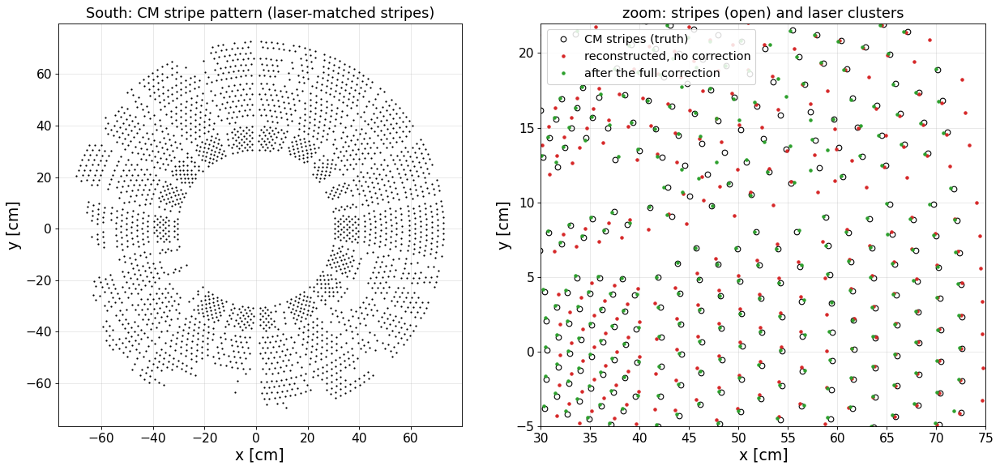

In [2]:
low, high = v.blocks_low_high()
def truth_xy(stage, blk='79513_00000'):
    a = c.load(f'T_{stage}', blk)
    tR = a[:, 1] - a[:, 3] / 10.0                 # truth = reco - residual (dR mm -> cm)
    tphi = a[:, 2] - a[:, 4] / 10.0 / a[:, 1]     # R dphi mm -> rad
    return a, tR, tphi
fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
cfg('raw', 'sc16', extra='run 79513 block 0, South')
for stage, col, lab in (('raw', 'tab:red', 'reconstructed, no correction'), ('sc16', 'tab:green', 'after the full correction')):
    a, tR, tphi = truth_xy(stage)
    s = a[:, 0] == 0
    if stage == 'raw':
        axs[0].plot(tR[s] * np.cos(tphi[s]), tR[s] * np.sin(tphi[s]), '.', ms=2, color='k', label='CM stripes (truth)')
        axs[1].plot(tR[s] * np.cos(tphi[s]), tR[s] * np.sin(tphi[s]), 'o', ms=6, mfc='none', color='k', label='CM stripes (truth)')
    axs[1].plot(a[s, 1] * np.cos(a[s, 2]), a[s, 1] * np.sin(a[s, 2]), '.', ms=6, color=col, label=lab)
axs[0].set_aspect('equal'); axs[0].set_xlabel('x [cm]'); axs[0].set_ylabel('y [cm]'); axs[0].set_title('South: CM stripe pattern (laser-matched stripes)')
axs[1].set_xlim(30, 75); axs[1].set_ylim(-5, 22); axs[1].set_xlabel('x [cm]'); axs[1].set_ylabel('y [cm]')
axs[1].set_title('zoom: stripes (open) and laser clusters'); axs[1].legend(loc='upper left')
fig.tight_layout(); show(fig)

## 2. Ben-style view (matcher QA): every matched cluster
**What is plotted.** Each point is one laser cluster matched to its CM stripe: dR (left) and Δφ (right, rad) against R,
coloured by φ bin, as in the LaserClusterTruthMatcher QA. Uncorrected and fully corrected, for each side (79513 block 0).

CONFIG  raw    : no correction
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        run 79513 block 0, South


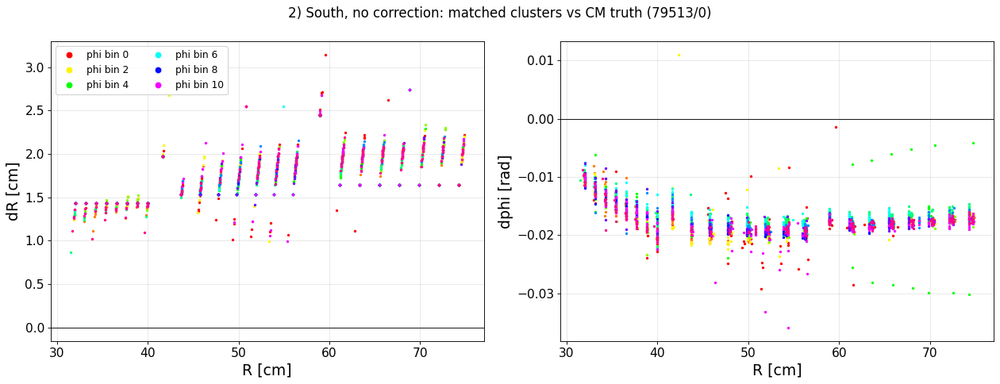

CONFIG  raw    : no correction
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        run 79513 block 0, North


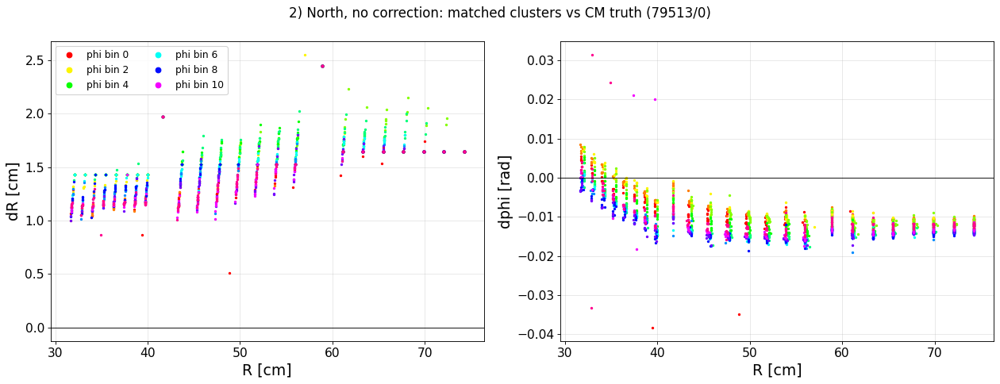

In [3]:
def ben_scatter(stage, side):
    a = c.load(f'T_{stage}', '79513_00000'); a = a[a[:, 0] == side]
    sec = np.floor((a[:, 2] % (2 * np.pi)) / (np.pi / 6)).astype(int)
    fig, axs = b.pair(f"2) {c.SIDES[side]}, {b.STG[stage][0]}: matched clusters vs CM truth (79513/0)")
    for k, col in zip(range(12), plt.cm.hsv(np.linspace(0, 0.92, 12))):
        sel = sec == k
        axs[0].plot(a[sel, 1], a[sel, 3] / 10, '.', ms=4, color=col, label=f"phi bin {k}" if k % 2 == 0 else None)
        axs[1].plot(a[sel, 1], a[sel, 4] / 10 / a[sel, 1], '.', ms=4, color=col)
    axs[0].set_ylabel('dR [cm]'); axs[1].set_ylabel('dphi [rad]')
    for ax in axs:
        ax.set_xlabel('R [cm]'); ax.axhline(0, color='k', lw=0.8)
    axs[0].legend(fontsize=11, markerscale=3, ncol=2); fig.tight_layout()
    return fig
for side in (0, 1):
    cfg('raw', 'sc16', extra=f'run 79513 block 0, {c.SIDES[side]}')
    show(ben_scatter('raw', side))

**The same at the production (CDB) keff.** keff = the run's CDB keff × the segment current correction (79513/0: South
1.589, North 1.590), with the α 2.0 map and with the default CDB map.

CONFIG  cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        cdbmap : default CDB map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        run 79513 block 0, South


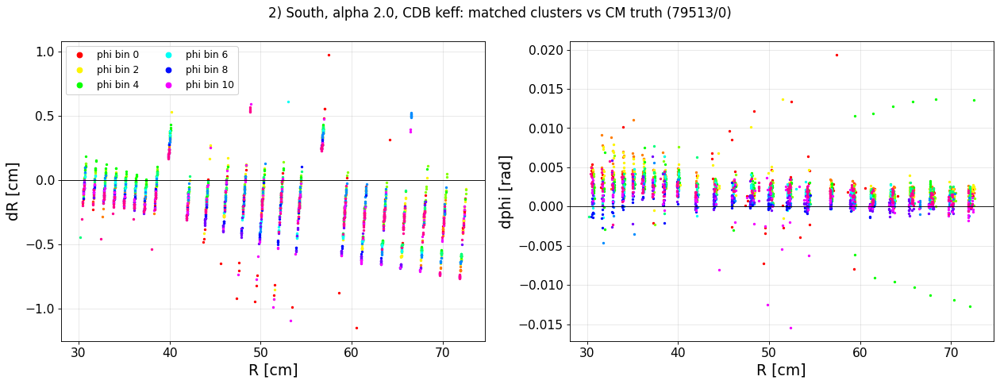

CONFIG  cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        cdbmap : default CDB map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        run 79513 block 0, North


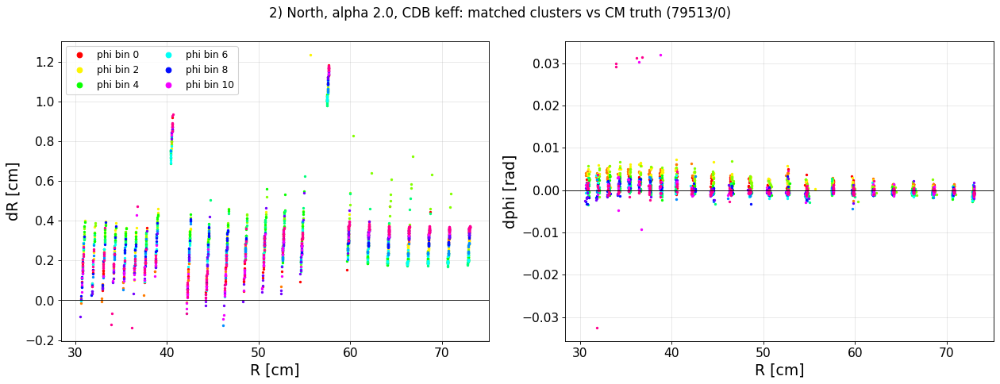

In [4]:
for side in (0, 1):
    cfg('cdbk', 'cdbmap', extra=f'run 79513 block 0, {c.SIDES[side]}')
    show(ben_scatter('cdbk', side))

### 2c. Ben's matcher QA graphs (LaserClusterTruthMatcher output, 79513 block 0)
**What is plotted.** The matcher's own TGraphs: ΔR and Δφ vs R_reco in 38 φ bins (all bins overlaid, colour = φ bin)
for South (negz) and North (posz). Shown for: no correction, static correction only, and the α 1.6 map at a = 0.39 ×
I_R1 (keff South 1.344 / North 1.282, close to the space-charge keff 1.281 / 1.347). Then the matcher's reconstructed vs
truth points, and its integrated distortion maps.

Welcome to JupyROOT 6.30/06
CONFIG  run 79513 block 0, no PHGarfield correction


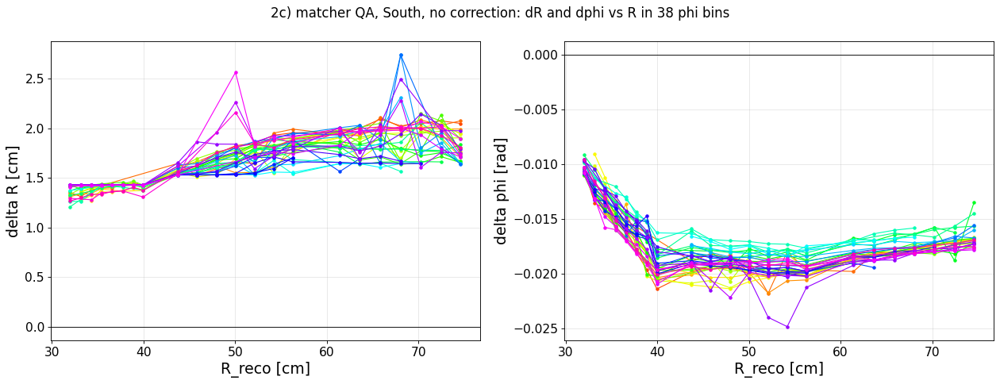

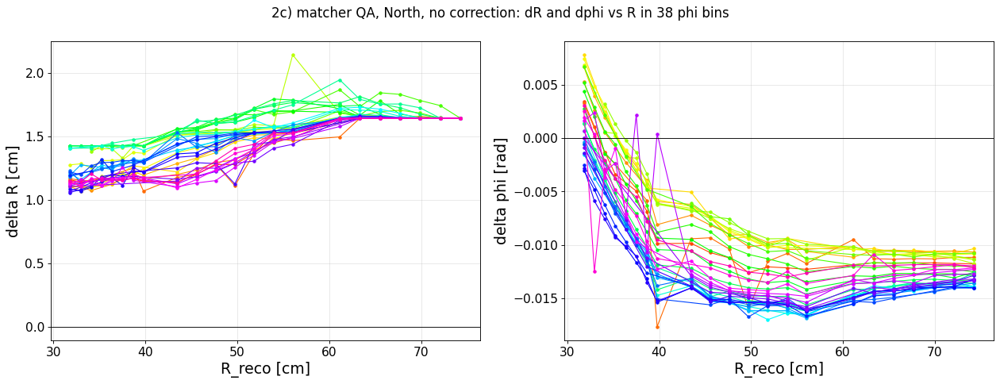

CONFIG  run 79513 block 0, static correction only (z -40 mm, tilt 0.16/0.85, P/T, IFC automatic), keff 0


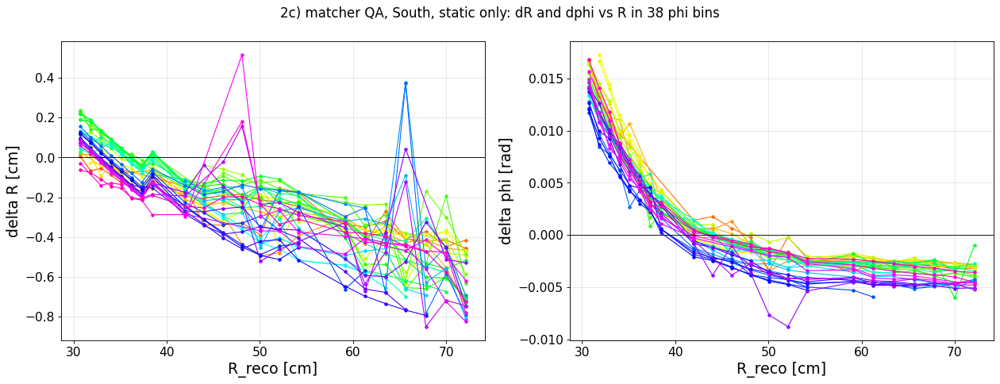

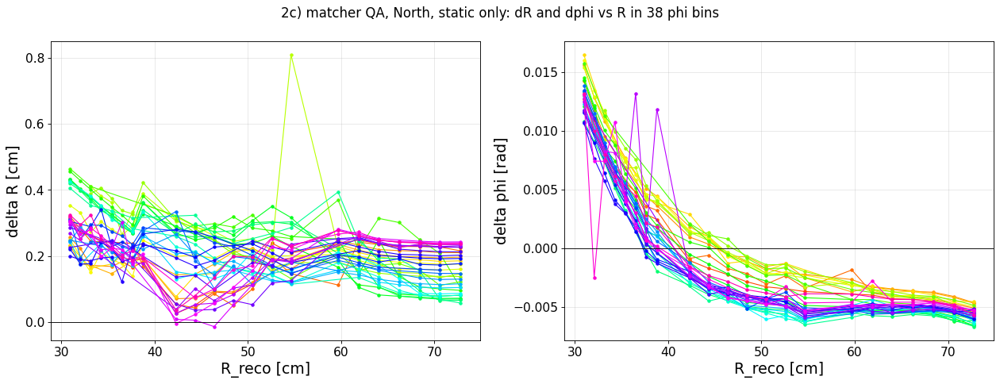

CONFIG  run 79513 block 0, default CDB map, keff = CDB x current = S 1.589 / N 1.590; + static


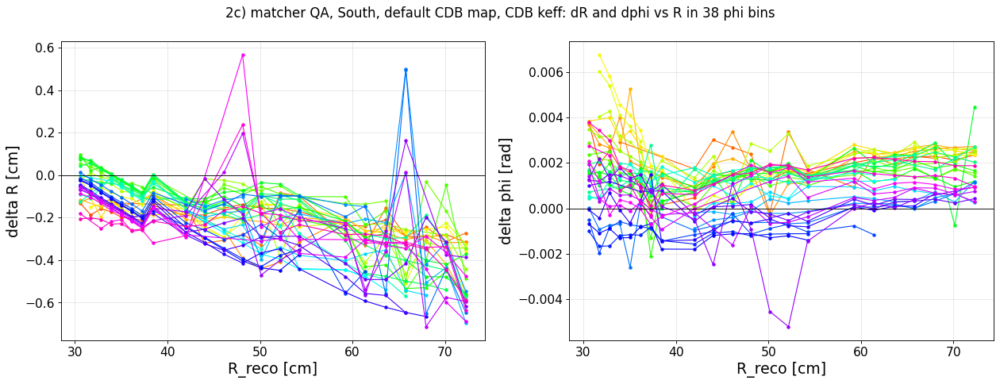

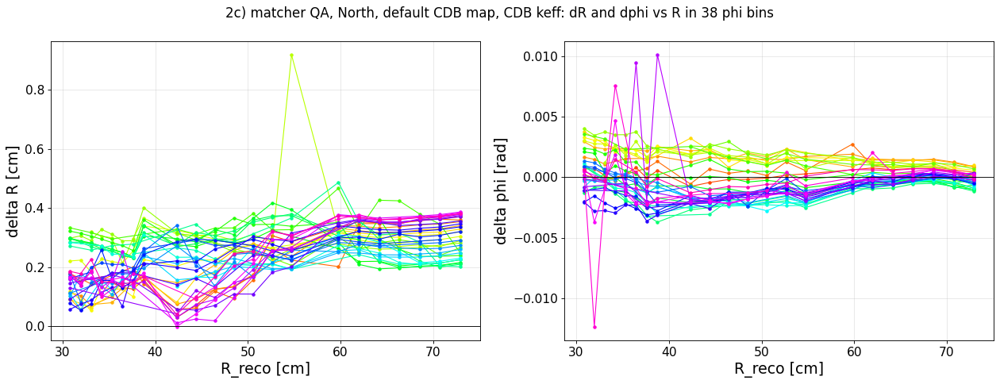

CONFIG  run 79513 block 0, no PHGarfield correction


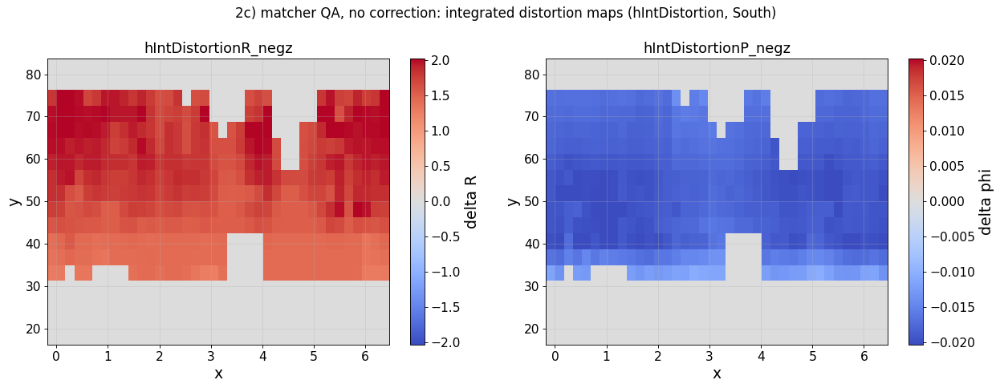

CONFIG  run 79513 block 0, default CDB map, keff = CDB x current = S 1.589 / N 1.590; + static


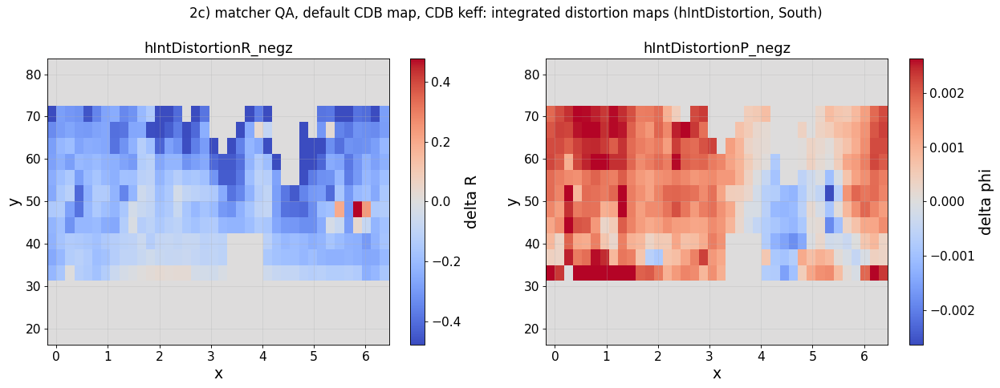

In [5]:
import ROOT
ROOT.gROOT.SetBatch(True)
TALK = 'data/talk'
FILES = (('noGarfield', 'no correction', 'no PHGarfield correction'),
         ('st_nom', 'static only', 'static correction only (z -40 mm, tilt 0.16/0.85, P/T, IFC automatic), keff 0'),
         ('cdbmap', 'default CDB map, CDB keff', 'default CDB map, keff = CDB x current = S 1.589 / N 1.590; + static'))
def graphs(tag, side, what):
    f = ROOT.TFile.Open(f'{TALK}/79513_0_{tag}.root'); z = 'negz' if side == 0 else 'posz'
    out = []
    for i in range(38):
        g = f.Get(f'{what}_phiBin{i}_{z}')
        if g and g.GetN():
            out.append((i, np.array([g.GetX()[j] for j in range(g.GetN())]), np.array([g.GetY()[j] for j in range(g.GetN())])))
    f.Close()
    return out
def ben_graphs(tag, lab):
    figs = []
    for side in (0, 1):
        fig, axs = b.pair(f"2c) matcher QA, {c.SIDES[side]}, {lab}: dR and dphi vs R in 38 phi bins")
        for ax, what, yl in ((axs[0], 'dR', 'delta R [cm]'), (axs[1], 'dPhi', 'delta phi [rad]')):
            for i, x, y in graphs(tag, side, what):
                ax.plot(x, y, '-o', ms=3, lw=1, color=plt.cm.hsv(i / 38 * 0.92))
            ax.set_xlabel('R_reco [cm]'); ax.set_ylabel(yl); ax.axhline(0, color='k', lw=0.8)
        fig.tight_layout(); figs.append(fig)
    return figs
for tag, lab, conf in FILES:
    print('CONFIG  run 79513 block 0, ' + conf)
    show(*ben_graphs(tag, lab))
# reco vs truth points and the integrated distortion maps
for tag, lab, conf in (FILES[0], FILES[2]):
    print('CONFIG  run 79513 block 0, ' + conf)
    f = ROOT.TFile.Open(f'{TALK}/79513_0_{tag}.root')
    # the matcher stores the points as (phi [rad], R [cm]): x-y view and a zoomed R-phi view
    #fig, axs = plt.subplots(1, 2, figsize=(16, 8))
    #fig.suptitle(f"2c) matcher QA, {lab}: reconstructed (colour) and truth (black) CM points, x-y", fontsize=17)
    #fig2, axs2 = b.pair(f"2c) matcher QA, {lab}: the same, R vs phi (zoom 0-60 deg)")
    #for side, z in ((0, 'negz'), (1, 'posz')):
    #    for nm, col, ms in ((f'gr_truthPoints_{z}', 'k', 3), (f'gr_recoPoints_{z}', 'tab:red' if tag == 'noGarfield' else 'tab:green', 2)):
    #        g = f.Get(nm)
    #        if g and g.GetN():
    #            ph = np.array([g.GetX()[j] for j in range(g.GetN())]); rr = np.array([g.GetY()[j] for j in range(g.GetN())])
    #            lab3 = 'truth (CM stripes)' if 'truth' in nm else 'reconstructed'
    #            axs[side].plot(rr * np.cos(ph), rr * np.sin(ph), '.', ms=ms, color=col, label=lab3)
    #            sel = (ph >= 0) & (ph < np.pi / 3)
    #            axs2[side].plot(np.degrees(ph[sel]), rr[sel], '.', ms=ms + 1, color=col, label=lab3)
    #    axs[side].set_title(c.SIDES[side]); axs[side].set_aspect('equal'); axs[side].set_xlabel('x [cm]'); axs[side].set_ylabel('y [cm]')
    #    axs2[side].set_title(c.SIDES[side]); axs2[side].set_xlabel('phi [deg]'); axs2[side].set_ylabel('R [cm]')
    #axs[1].legend(markerscale=5, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    #axs2[1].legend(markerscale=4, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    #fig.tight_layout(); fig2.tight_layout(); show(fig, fig2)
    fig, axs = b.pair(f"2c) matcher QA, {lab}: integrated distortion maps (hIntDistortion, South)")
    for ax, nm, lab2 in ((axs[0], 'hIntDistortionR_negz', 'delta R'), (axs[1], 'hIntDistortionP_negz', 'delta phi')):
        h = f.Get(nm)
        if h:
            nx, ny = h.GetNbinsX(), h.GetNbinsY()
            A = np.array([[h.GetBinContent(i, j) for i in range(1, nx + 1)] for j in range(1, ny + 1)])
            xe = [h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)]; ye = [h.GetYaxis().GetBinLowEdge(j) for j in range(1, ny + 2)]
            vmax = np.nanpercentile(np.abs(A[A != 0]), 95) if (A != 0).any() else 1
            im = ax.pcolormesh(xe, ye, A, cmap='coolwarm', vmin=-vmax, vmax=vmax); fig.colorbar(im, ax=ax, label=lab2)
            ax.set_xlabel(h.GetXaxis().GetTitle() or 'x'); ax.set_ylabel(h.GetYaxis().GetTitle() or 'y'); ax.set_title(nm)
    fig.tight_layout(); show(fig)
    f.Close()

### 2b. The same as medians: residual vs R in φ slices
**What is plotted.** Cluster minus matched stripe, RΔφ (top) and dR (bottom), against R. Colour = φ slice of 30°.
Raw on the left, after the full correction on the right (South, 79513/0).

**Why.** This is the classic CM-laser picture. Before correction RΔφ reaches −10 … −20 mm and depends on R and φ; after
correction everything collapses to around 0. The remaining structure is what the rest of the talk is about.

**Note on raw dR (+12 … +25 mm).** Without any correction, the clusters are so far off that the nearest stripe is
often the neighbouring stripe row (row spacing 11–22 mm). The raw dR vs truth is therefore partly a wrong-row offset.
After the static correction, the clusters land on the right rows (section 3, matching QA). That is why the matching
is done after the correction.

CONFIG  raw    : no correction
        cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        run 79513 block 0, vs CM truth


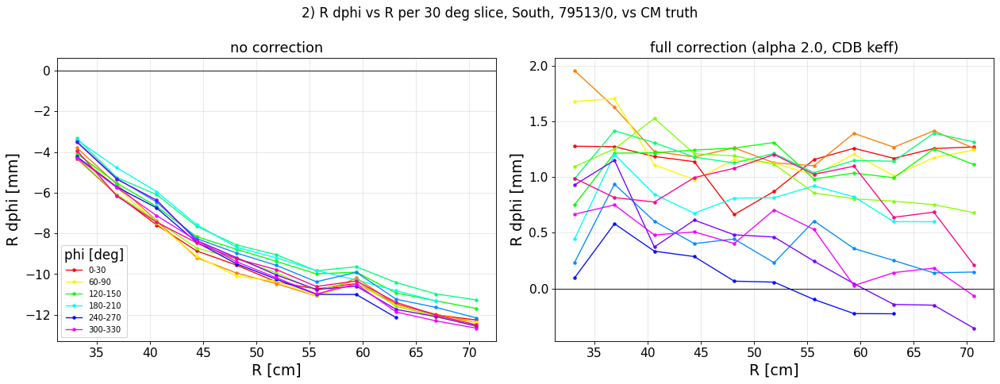

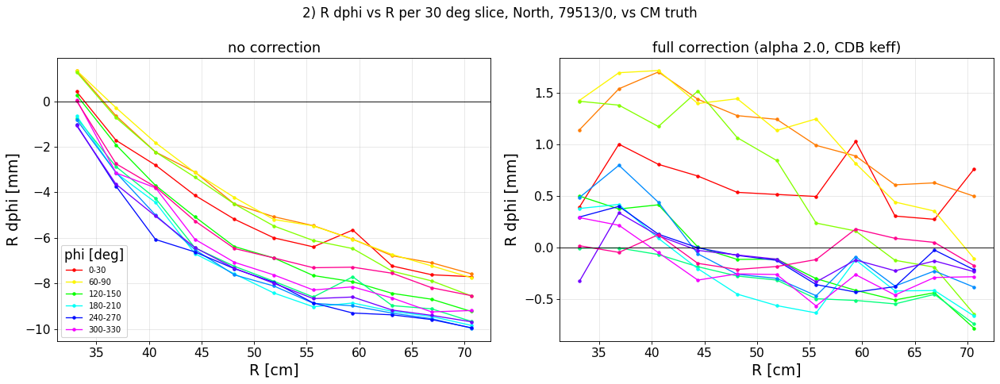

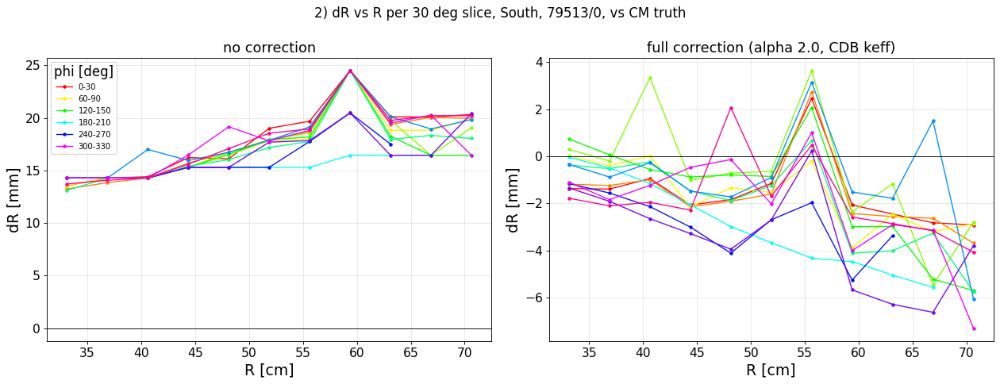

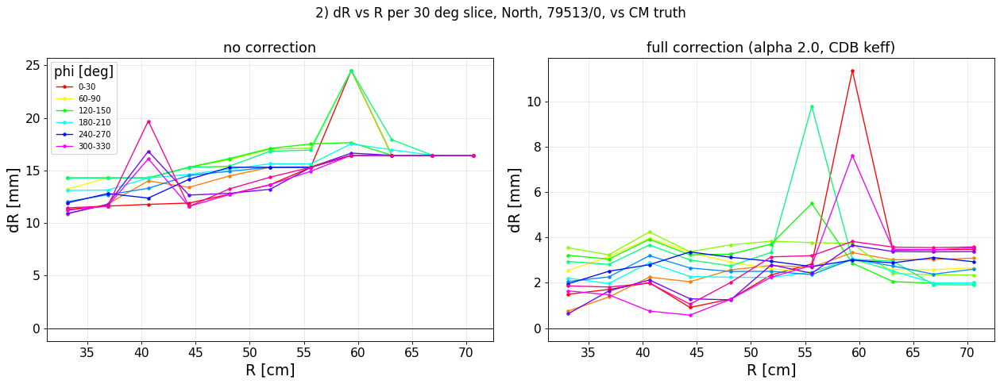

In [6]:
def ben(stage, side, q, ax, title):
    a = c.load(f'T_{stage}', '79513_00000'); a = a[a[:, 0] == side]
    sec = np.floor((a[:, 2] % (2 * np.pi)) / (np.pi / 6)).astype(int)
    for k, col in zip(range(12), plt.cm.hsv(np.linspace(0, 0.92, 12))):
        m = c.ring_stats(a[sec == k], side, q)[0]
        ax.plot(R, m, '-o', ms=3, color=col, lw=1.2, label=f"{30*k}-{30*k+30}" if k % 2 == 0 else None)
    ax.set_title(title); ax.set_xlabel('R [cm]'); ax.set_ylabel(b.QL[q]); ax.axhline(0, color='k', lw=0.8)
cfg('raw', 'cdbk', extra='run 79513 block 0, vs CM truth')
for q in (4, 3):
    for side in (0, 1):
        fig, axs = b.pair(f"2) {b.QL[q].split(' [')[0]} vs R per 30 deg slice, {c.SIDES[side]}, 79513/0, vs CM truth")
        ben('raw', side, q, axs[0], 'no correction'); ben('cdbk', side, q, axs[1], 'full correction (alpha 2.0, CDB keff)')
        axs[0].legend(fontsize=9, title='phi [deg]'); fig.tight_layout(); show(fig)

### 2d. The same φ-slice view with the production (CDB) keff
**What is plotted.** RΔφ vs R per 30° slice for:
- the α 2.0 map at the CDB keff (left);
- the default CDB map at the CDB keff (right).

The keff is the run's CDB keff × the segment current correction, the same as PHGarfield without an override (79513/0:
South 1.589, North 1.590). Shown vs CM truth, then for beam − no beam 75073 (space charge only), next to α 1.6 at the
space-charge keff.

CONFIG  raw    : no correction
        cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        beam - no beam 75073, all 11 low-lumi blocks pooled


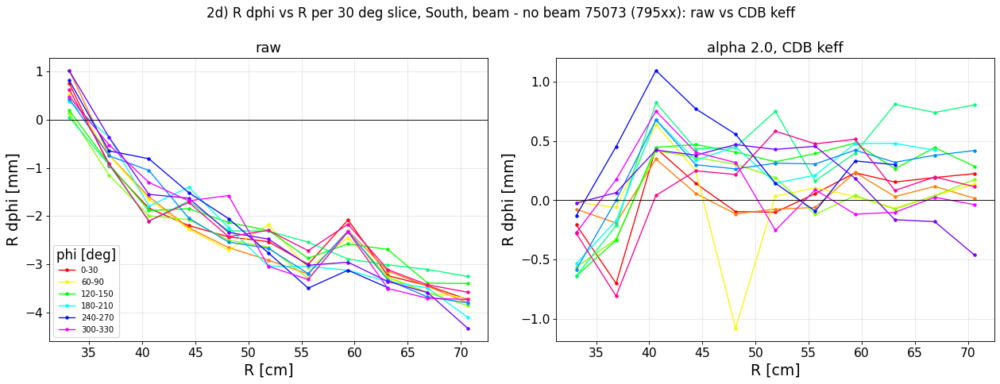

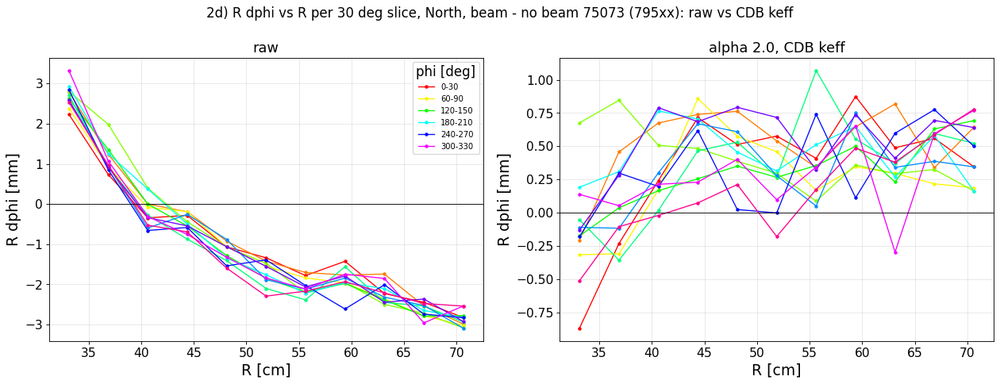

CONFIG  cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        beam - no beam 75073, all 11 low-lumi blocks pooled


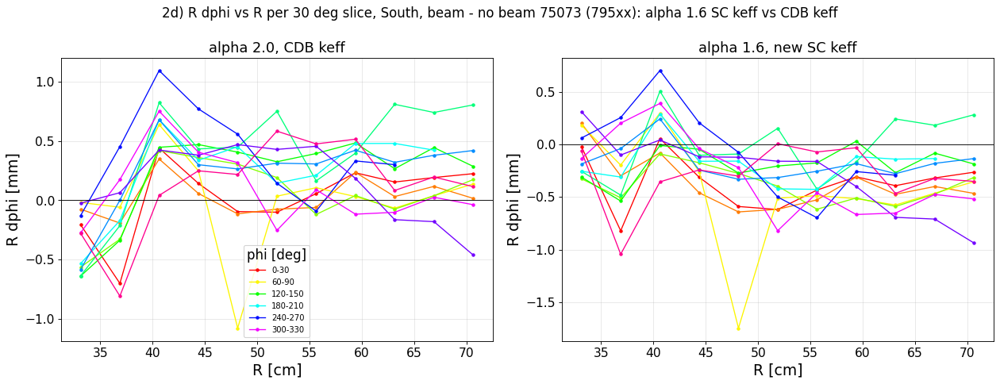

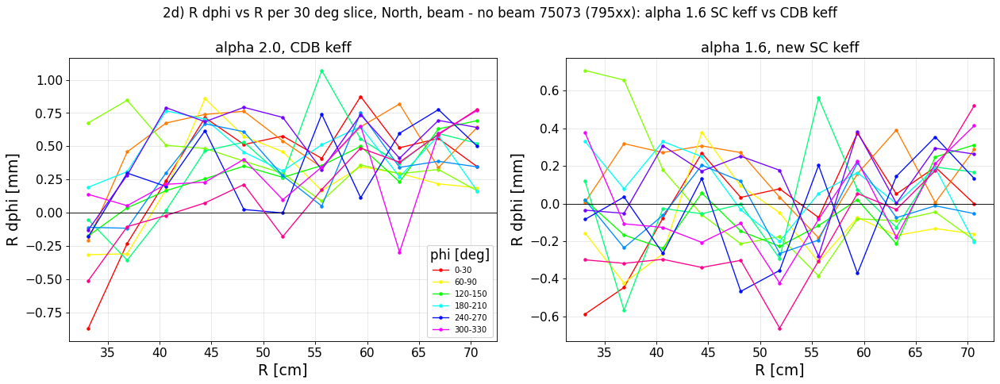

In [7]:
def ben_c(stage, side, q, ax, title, cmp='T', blks=('79513_00000',)):
    a = c.load_many(f'{cmp}_{stage}', list(blks)); a = a[a[:, 0] == side]
    sec = np.floor((a[:, 2] % (2 * np.pi)) / (np.pi / 6)).astype(int)
    for k, col in zip(range(12), plt.cm.hsv(np.linspace(0, 0.92, 12))):
        m = c.ring_stats(a[sec == k], side, q)[0]
        ax.plot(R, m, '-o', ms=3, color=col, lw=1.2, label=f"{30*k}-{30*k+30}" if k % 2 == 0 else None)
    ax.set_title(title); ax.set_xlabel('R [cm]'); ax.set_ylabel(b.QL[q]); ax.axhline(0, color='k', lw=0.8)



cfg('raw', 'cdbk', extra='beam - no beam 75073, all 11 low-lumi blocks pooled')
for side in (0, 1):
    fig, axs = b.pair(f"2d) R dphi vs R per 30 deg slice, {c.SIDES[side]}, beam - no beam 75073 (795xx): raw vs CDB keff")
    ben_c('raw', side, 4, axs[0], 'raw', cmp='NB75', blks=low); ben_c('cdbk', side, 4, axs[1], 'alpha 2.0, CDB keff', cmp='NB75', blks=low)
    axs[0].legend(fontsize=9, title='phi [deg]'); fig.tight_layout(); show(fig)

cfg('cdbk', 'sc16', extra='beam - no beam 75073, all 11 low-lumi blocks pooled')
for side in (0, 1):
    fig, axs = b.pair(f"2d) R dphi vs R per 30 deg slice, {c.SIDES[side]}, beam - no beam 75073 (795xx): alpha 1.6 SC keff vs CDB keff")
    ben_c('cdbk', side, 4, axs[0], 'alpha 2.0, CDB keff', cmp='NB75', blks=low); ben_c('sc16', side, 4, axs[1], 'alpha 1.6, new SC keff', cmp='NB75', blks=low)
    axs[0].legend(fontsize=9, title='phi [deg]'); fig.tight_layout(); show(fig)

## 4. What has to be corrected
**What is plotted.** The median per R ring (all φ, 11 low-lumi blocks): no correction (grey), static correction only
(cyan), and the full correction (green: α 1.6 map at the space-charge keff).

- Vs truth: the full distortion.
- Beam − no beam: space charge only.
- Beam − field off: everything field-on.

CONFIG  raw    : no correction
        static : static correction only (z -40 mm, tilt 0.16/0.85 mrad, P/T CM field, IFC automatic), keff 0
        cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        11 low-lumi blocks pooled (795xx)


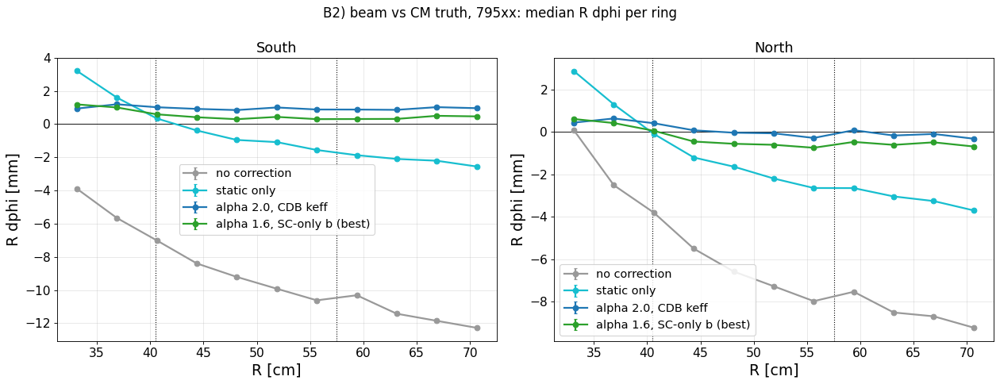

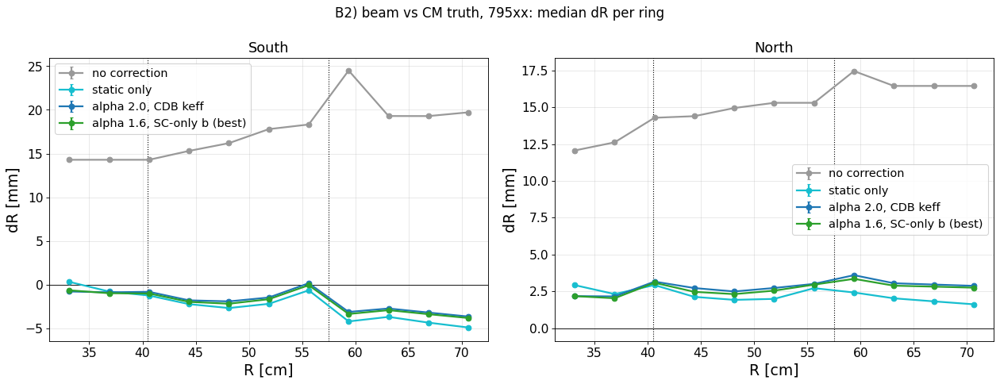

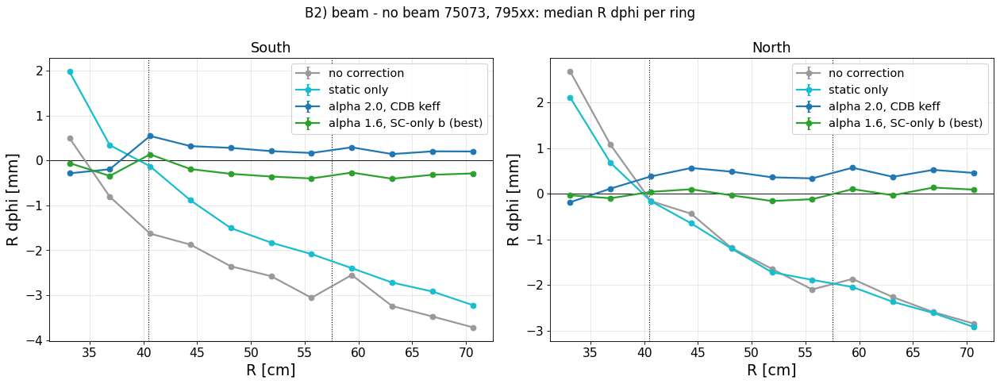

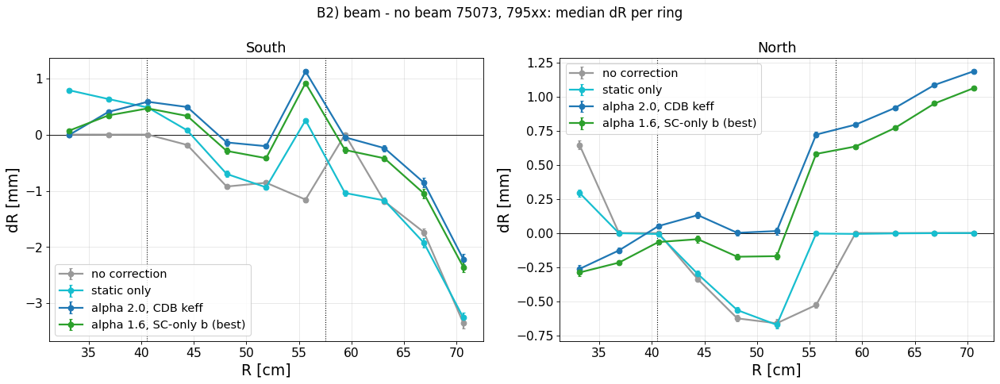

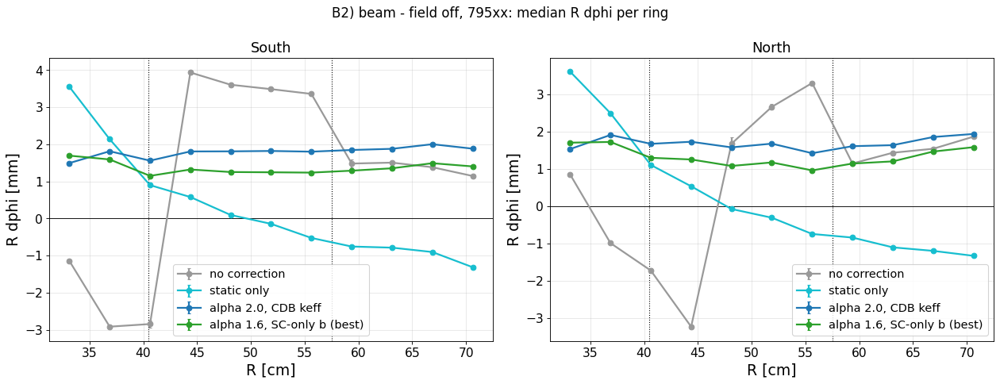

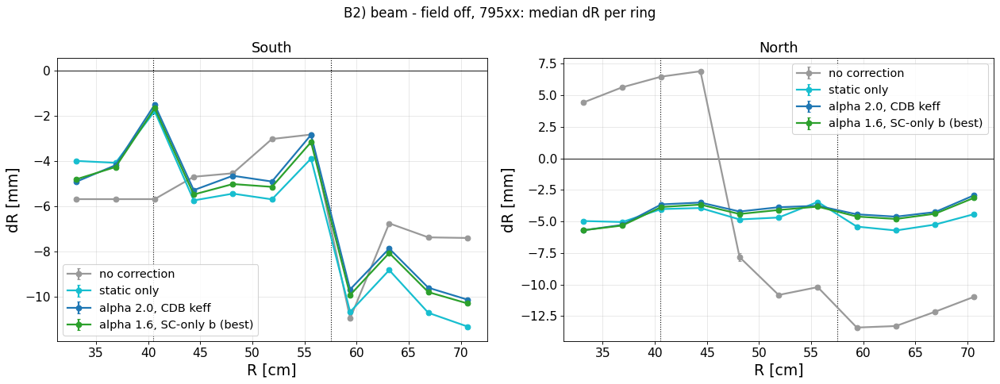

In [8]:
cfg('raw', 'static', 'cdbk', 'sc16', extra='11 low-lumi blocks pooled (795xx)')
for cmp in ('T', 'NB75', 'OFF'):
    show(b.b_vs_r(cmp, 4, names=('raw', 'static', 'cdbk', 'sc16')), b.b_vs_r(cmp, 3, names=('raw', 'static', 'cdbk', 'sc16')))

## 5. Step 1: space charge alone (beam − no beam)
**Why this reference first.** Beam and no-beam runs are both field on and corrected with the same static model, so the
static distortion, the stripe pattern and field off all cancel. What is left is space charge and our space-charge
correction, nothing else.

**Criterion.** Δφ(R) = RΔφ/R must be flat in R. A constant Δφ is just a rotation between the two runs (free). A slope is
a sagitta (curvature for tracks, 100 µm ≈ 0.7 mrad over 33–71 cm), and a 1/R shape is a DCA offset.

**What is plotted.** Beam − no beam per ring, in Δφ and RΔφ, for several configurations:
- α 1.6 and α 2.0 maps at their own space-charge keff;
- α 2.0 at the old laser-absolute keff;
- the default CDB map at the CDB keff.

CONFIG  raw    : no correction
        static : static correction only (z -40 mm, tilt 0.16/0.85 mrad, P/T CM field, IFC automatic), keff 0
        sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        sc20   : alpha 2.0 map, keff = 0.665 x I_side (79513/0: S 1.429, N 1.503); + static
        cdbk   : alpha 2.0 map, CDB keff x current (79513/0: S 1.589, N 1.590); + static
        final  : alpha 2.0 map, laser-absolute keff = 0.843 x I_side (79513/0: S 1.811, N 1.904); + static
        beam - no beam 75073, 795xx pooled


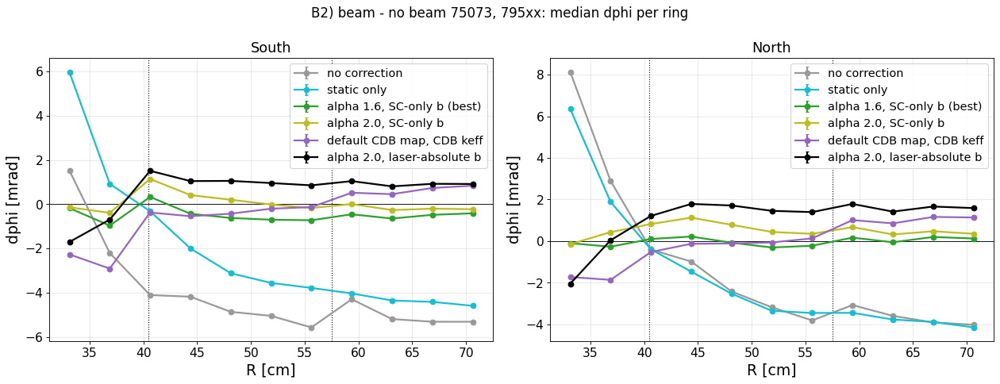

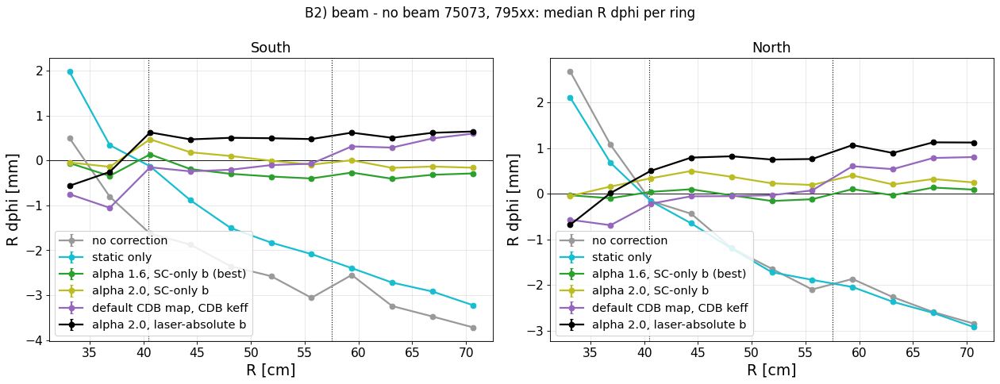

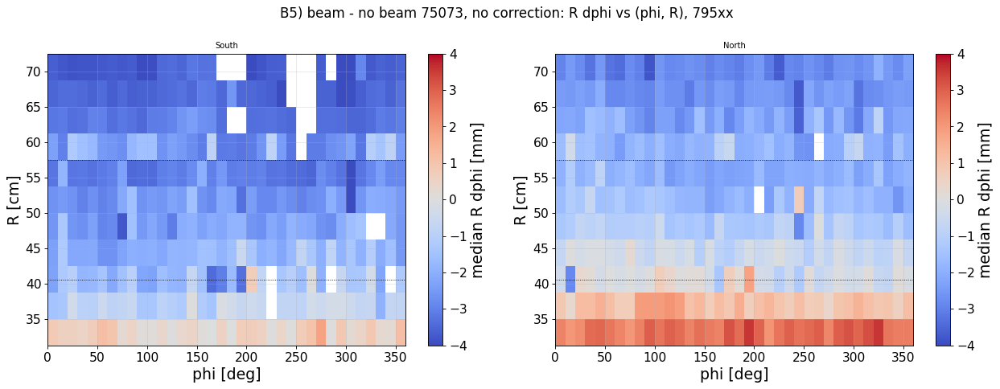

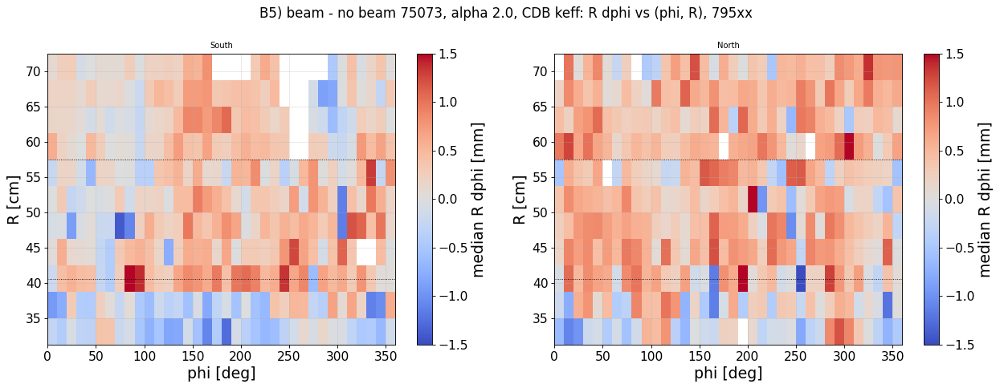

In [9]:
cfg('raw', 'static', 'sc16', 'sc20', 'cdbk', 'final', extra='beam - no beam 75073, 795xx pooled')
show(b.b_vs_r('NB75', 5), b.b_vs_r('NB75', 4))
#show(b.b_hist('NB75', 4), b.b_hist('NB75', 5))
show(b.b_map('NB75', 'raw', q=4, vlim=4), b.b_map('NB75', 'cdbk', q=4))

### 5a. The big scan: which map?
2780 laser jobs. 41 space-charge maps × keff = b × I_side (b 0.45–0.90) × 17 blocks. Maps:
- α = 1.6 / 1.8 / 2.0 (charge density ∝ R^−α);
- the inner kink at 22.75 / 25 / 27.5 cm and its width;
- with or without an outer fall-off at 72 cm;
- the old production maps and the default CDB map.

**What is plotted.** χ² of a flat Δφ(R) per map: one b for all 795xx blocks (blue), and b per run for 80892 / 81558
(orange). The right panel shows the best b per map.

CONFIG  big scan A: 41 maps x keff = b x I_side (b 0.45-0.90) x 17 blocks, z -40 mm, tilt 0.16/0.85, P/T, IFC automatic; beam - no beam 75073


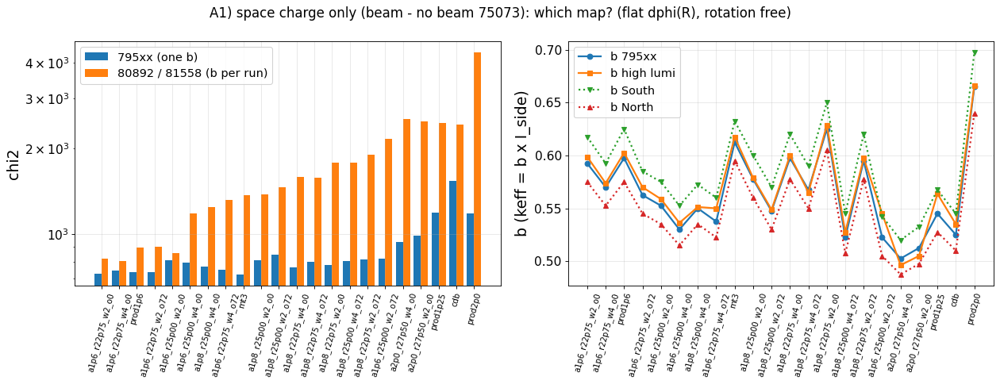

map                     b 795xx   chi2  b high   chi2    b S    b N
a1p6_r22p75_w2_o0         0.593    725   0.599    819  0.618  0.575
a1p6_r22p75_w4_o0         0.570    743   0.574    804  0.593  0.553
prod1p6                   0.598    737   0.603    898  0.625  0.575
a1p6_r22p75_w2_o72        0.563    737   0.570    903  0.585  0.545
a1p6_r25p00_w2_o0         0.553    808   0.559    860  0.575  0.535
a1p6_r25p00_w4_o0         0.530    793   0.536   1179  0.553  0.515
a1p8_r25p00_w4_o0         0.550    768   0.551   1247  0.573  0.535
a1p6_r22p75_w4_o72        0.538    751   0.550   1317  0.560  0.523
cdb                       0.525   1543   0.535   2425  0.545  0.510
prod2p0                   0.665   1183   0.666   4350  0.698  0.640


In [10]:
print("CONFIG  big scan A: 41 maps x keff = b x I_side (b 0.45-0.90) x 17 blocks, z -40 mm, tilt 0.16/0.85, P/T, IFC automatic; beam - no beam 75073")
fig, rows = b.a_ranking(); show(fig)
print(f"{'map':22s} {'b 795xx':>8s} {'chi2':>6s} {'b high':>7s} {'chi2':>6s} {'b S':>6s} {'b N':>6s}")
for r in rows[:8] + [x for x in rows if x['map'] in ('prod2p0', 'cdb')]:
    print(f"{r['map']:22s} {r['b_low']:8.3f} {r['chi2_low']:6.0f} {r['b_high']:7.3f} {r['chi2_high']:6.0f} {r['b_S']:6.3f} {r['b_N']:6.3f}")

**Take-away.**
- α 1.6 wins. α 2.0 fails badly at high luminosity.
- The details of the inner kink and outer edge matter little.

**What is plotted next.**
- χ² against the shape parameters.
- χ² against b.
- Δφ(R) per run for the best map and for α 2.0.

### 5b. keff is linear in the GEM current
**What is plotted.** The best b per run and side against the GEM current of the side (TPC_CONDITIONS, all-module
median). A flat b means keff ∝ current.

**Take-away.** With α 1.6, b ≈ 0.59–0.60 from 1.8 to 6.6 µA, the same at low and high luminosity. North needs about 7 %
less per µA than South.

### 5c. What is left: φ structure (module gains)
**What is plotted.**
- RΔφ vs φ for the three module rings (R1, R2, R3) of beam − no beam after the correction.
- The sagitta per 30° sector, per run.

The remaining sector-to-sector structure comes from the GEM module gains / IBF, the next tuning step.

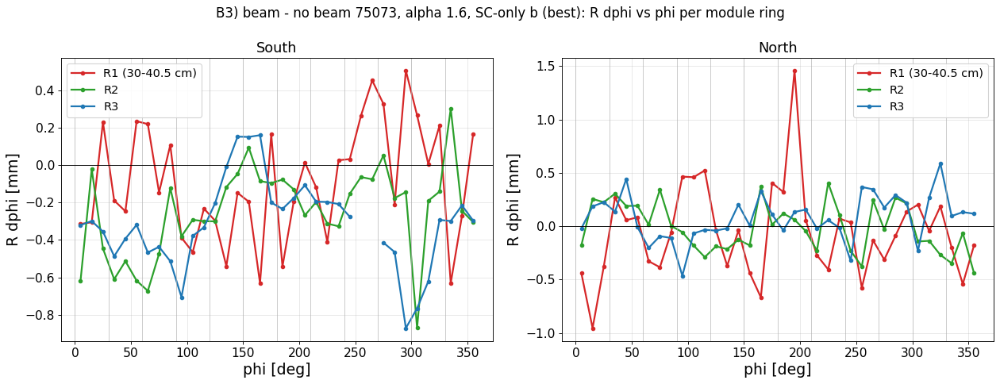

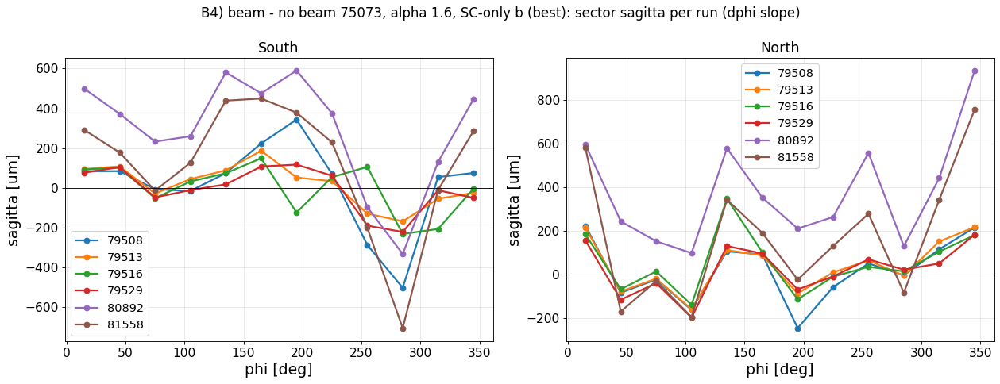

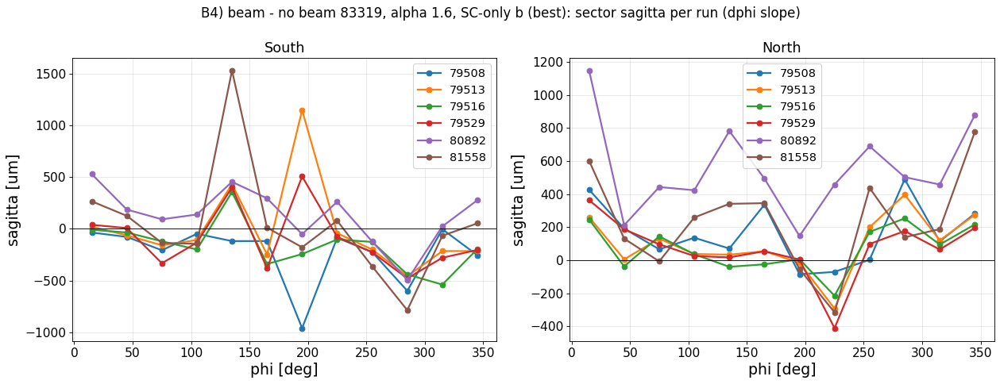

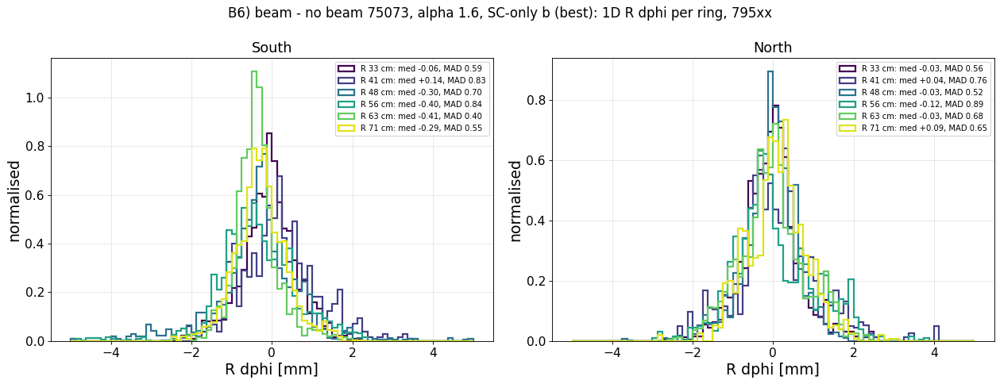

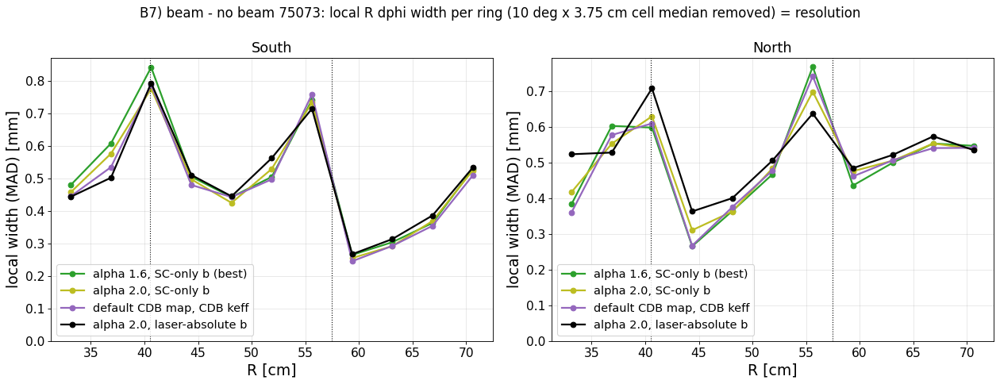

In [11]:
show(b.b_vs_phi('NB75', 4), b.b_sector_sag('NB75'), b.b_sector_sag('NB83'))
show(b.b_ring_1d('NB75', q=4), b.b_local_width())

### 5d. Beam − no beam in detail: rotation removed per φ, sagitta per φ, local RΔφ per layer
**What is plotted.**
- Per 30° sector, the median RΔφ vs R after removing that sector's rotation (the best straight line through R = 0,
  which a track absorbs). What remains is the DCA and the curvature that tracks would feel.
- The per-ring histograms after removing a straight line per 10° φ bin (what a high-pT track sees).
- The local residual: the cluster minus its 10° × 3.75 cm cell median, i.e. the resolution.

CONFIG  sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        sc20   : alpha 2.0 map, keff = 0.665 x I_side (79513/0: S 1.429, N 1.503); + static
        beam - no beam 75073, 795xx pooled


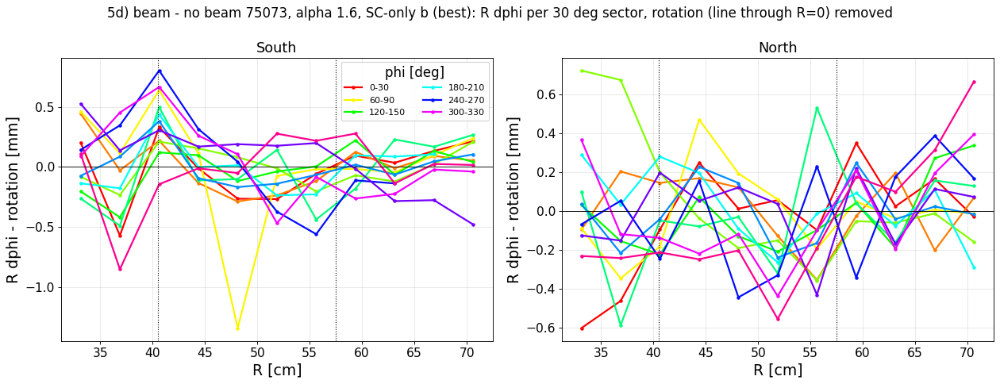

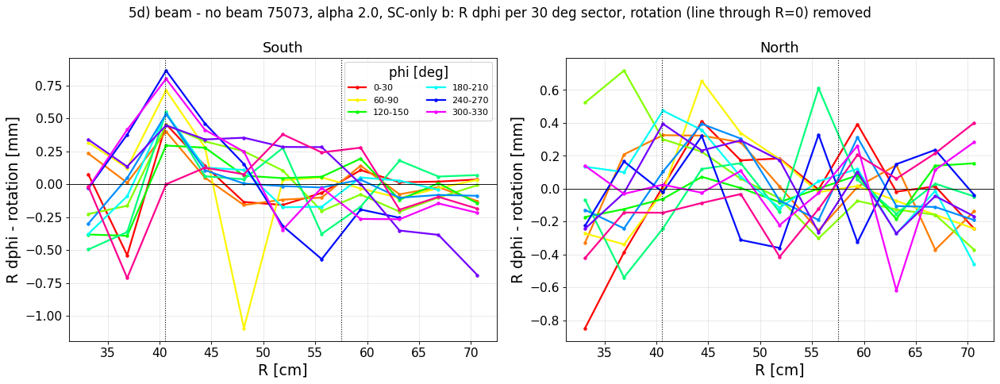

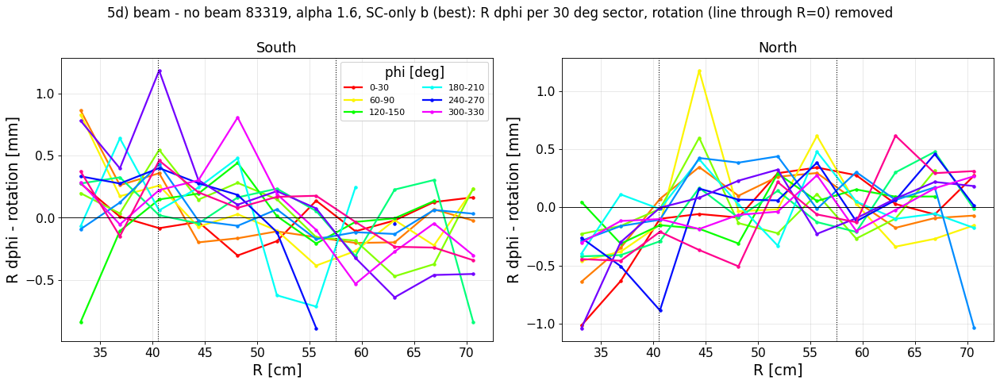

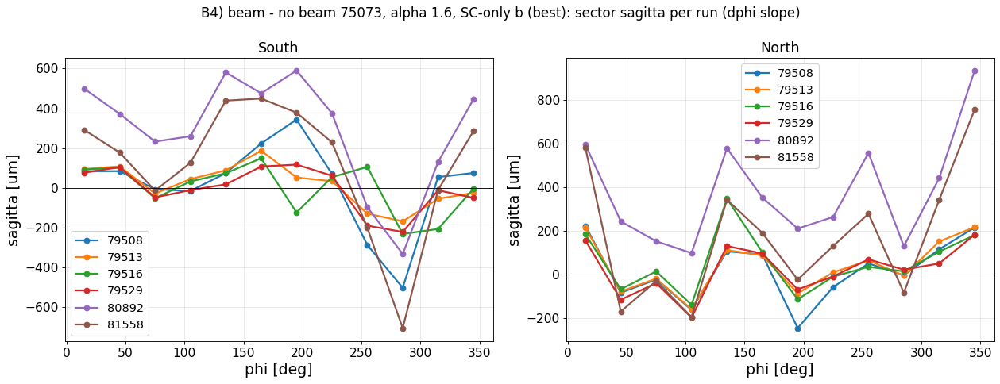

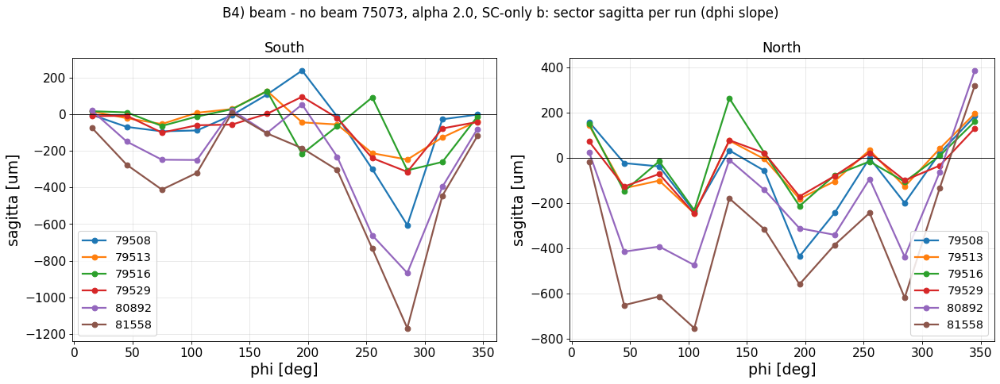

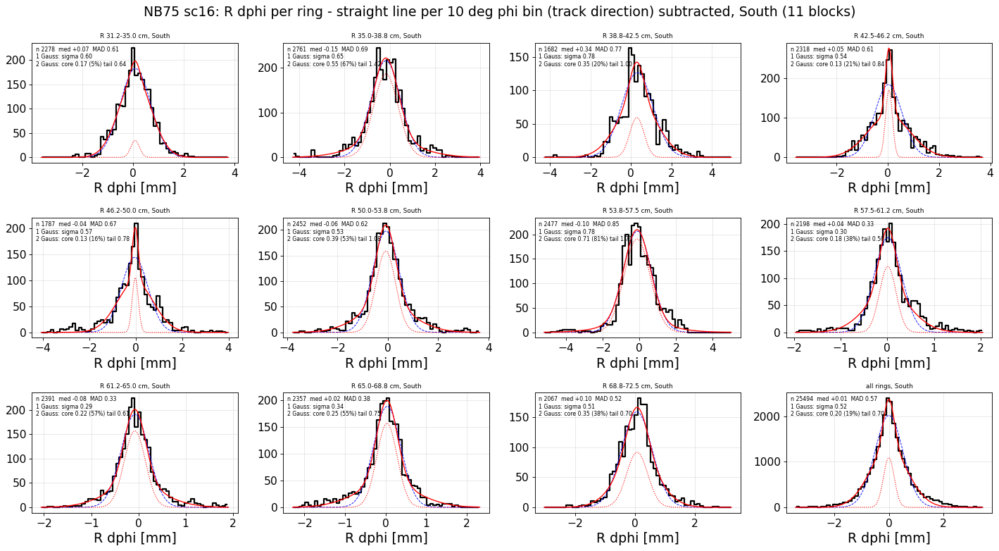

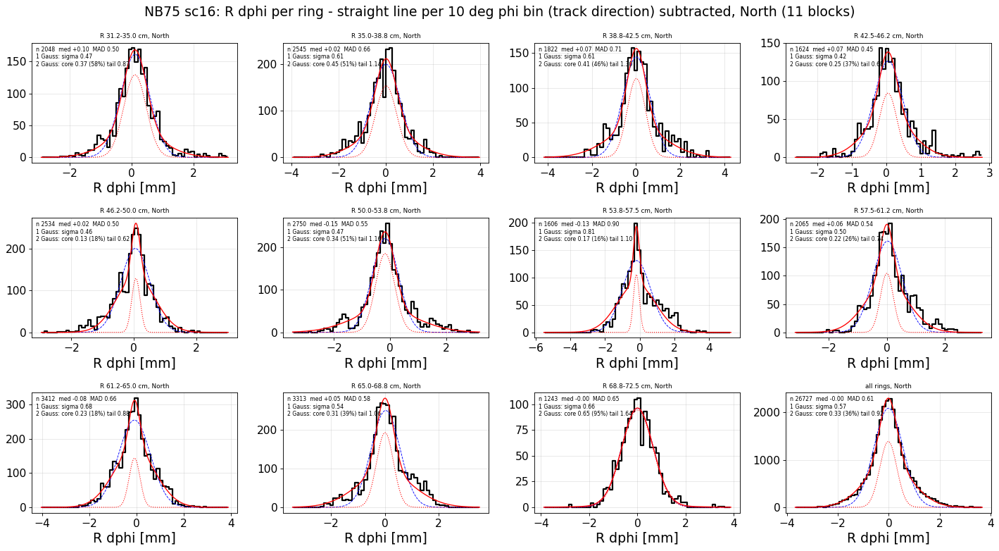

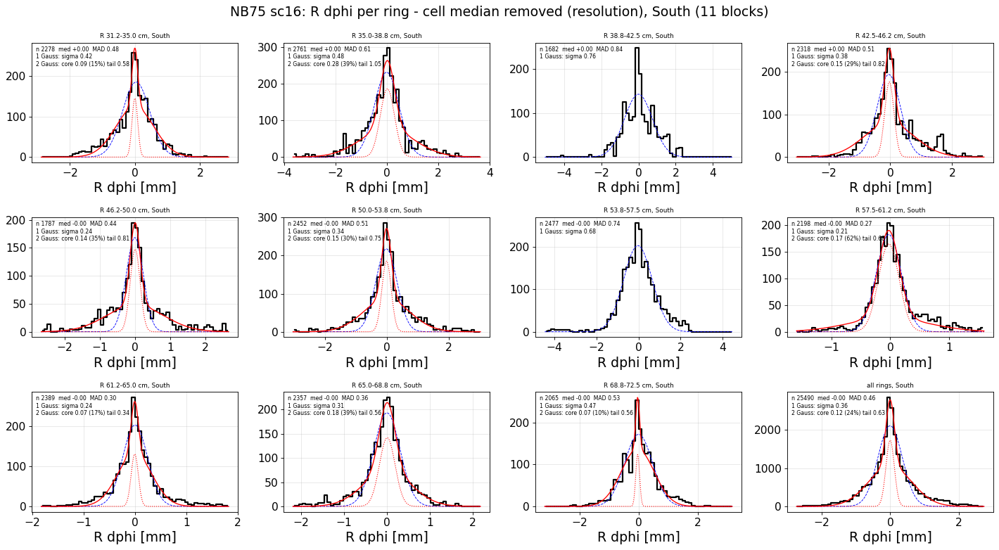

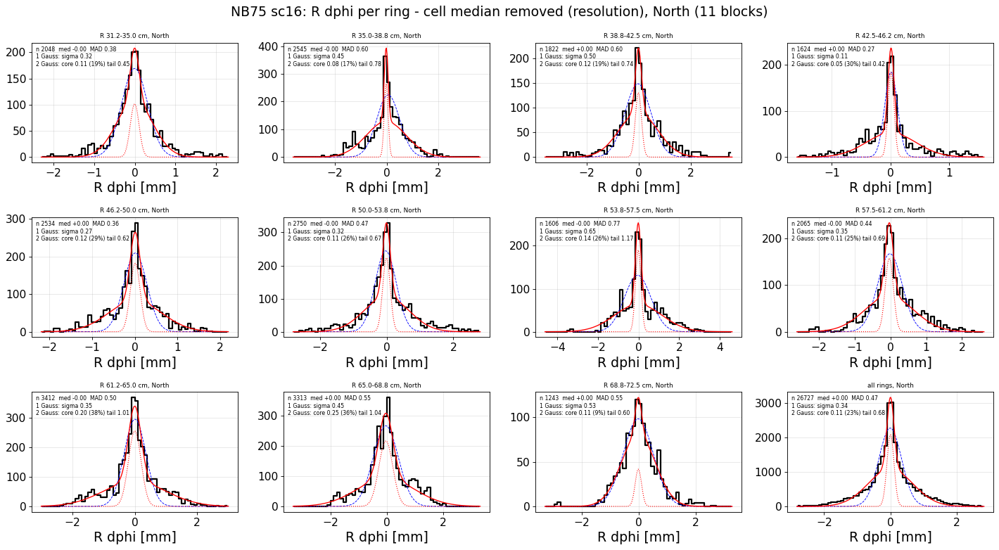

In [12]:
def rot_removed(cmp='NB75', st='sc16'):
    a_all = c.load_many(f'{cmp}_{st}', low)
    fig, axs = b.pair(f"5d) {b.CMPN[cmp]}, {b.STG[st][0]}: R dphi per 30 deg sector, rotation (line through R=0) removed")
    for s in (0, 1):
        a = a_all[a_all[:, 0] == s]; sec = np.floor((a[:, 2] % (2 * np.pi)) / (np.pi / 6)).astype(int)
        for k, col in zip(range(12), plt.cm.hsv(np.linspace(0, 0.92, 12))):
            m, e, _, _ = c.ring_stats(a[sec == k], s, 4); ok = np.isfinite(m)
            if ok.sum() < 5: continue
            rot = np.sum(m[ok] * R[ok]) / np.sum(R[ok] ** 2)
            axs[s].plot(R, m - rot * R, '-o', ms=3, color=col, label=f"{30*k}-{30*k+30}" if k % 2 == 0 else None)
        axs[s].set_title(c.SIDES[s])
    axs[0].legend(fontsize=10, title='phi [deg]', ncol=2)
    return b.finish(fig, axs, xl='R [cm]', yl='R dphi - rotation [mm]', mods=True, legend=False)
cfg('sc16', 'sc20', extra='beam - no beam 75073, 795xx pooled')
show(rot_removed('NB75', 'sc16'), rot_removed('NB75', 'sc20'), rot_removed('NB83', 'sc16'))
show(b.b_sector_sag('NB75', 'sc16'), b.b_sector_sag('NB75', 'sc20'))
show(*c.ring_hists('NB75', 'sc16', q=4, mode='line_phi'))
show(*c.ring_hists('NB75', 'sc16', q=4, mode='local'))

## 6. Step 2: why keff from beam − no beam is lower than expected
Three numbers for the same thing (keff = b × I_side):

| criterion | b |
|---|---|
| space charge only (beam − no beam), α 1.6 | ≈ 0.60 |
| tracks, α 2.0 map (charge-odd rDCA = 0, 79513) | ≈ 0.72 South / 0.76 North |
| laser vs truth / field off ("absolute": DCA and sagitta = 0), α 2.0 | ≈ 0.84 |

The absolute fit pushed keff up. Some distortion that is **not** space charge was being absorbed into keff.

**What is plotted.** Beam vs field off and beam vs truth per ring. At the space-charge keff (green) a curvature is
left. The laser-absolute b (black) removes it, but over-corrects beam − no beam (section 5).

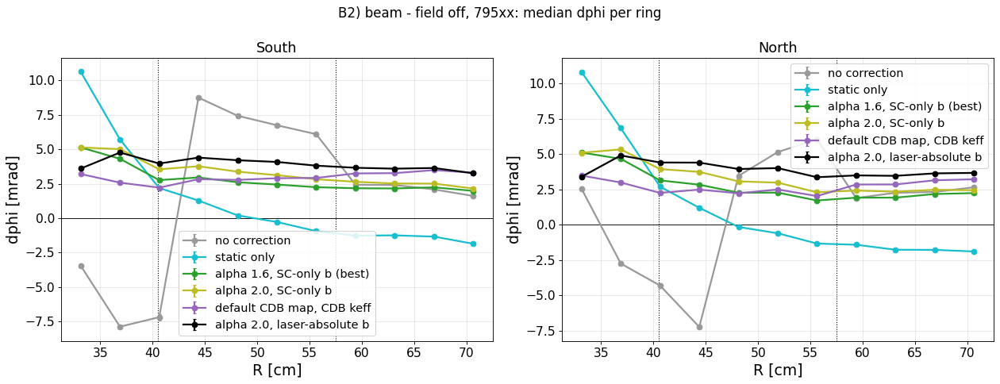

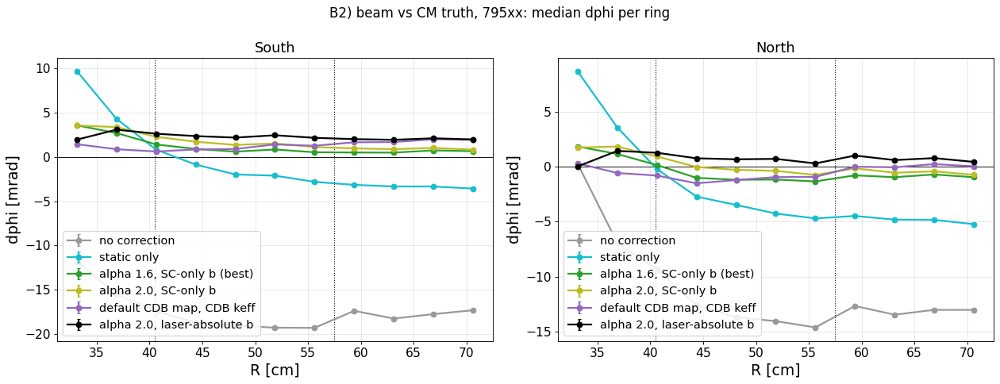

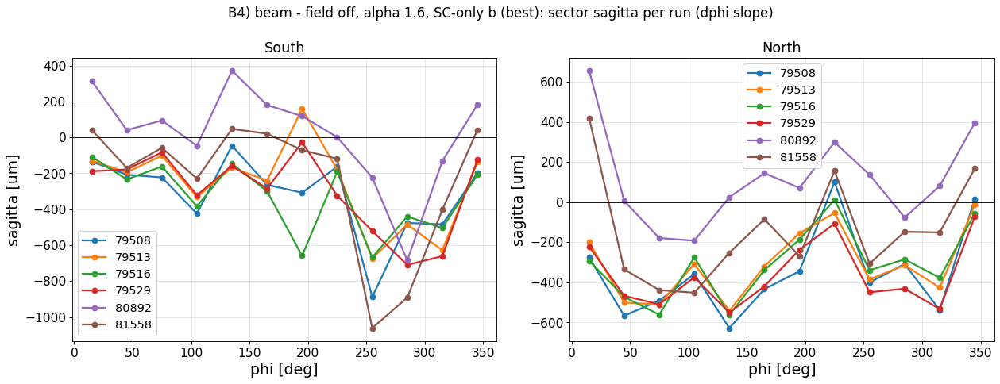

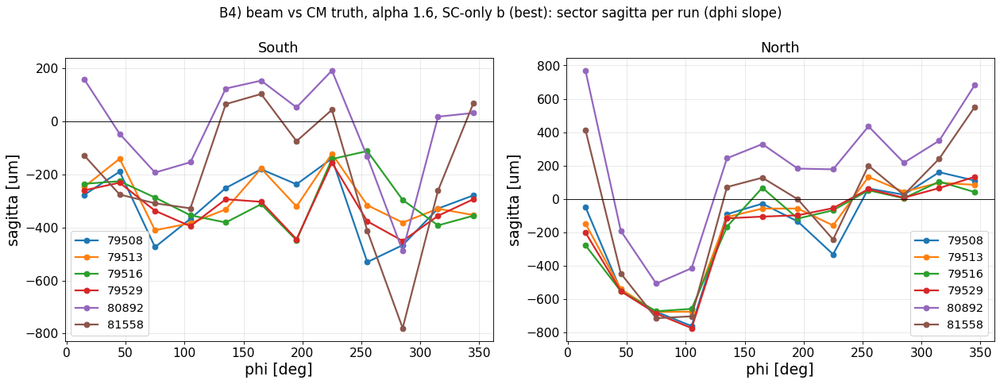

In [13]:
show(b.b_vs_r('OFF', 5), b.b_vs_r('T', 5))
show(b.b_sector_sag('OFF'), b.b_sector_sag('T'))

### 6-votes. Which keff does each reference want?
**What is plotted.** For the best map (α 1.6) and the old α 2.0, from the big scan (all 795xx blocks, both sides), the b
preferred by each reference and criterion:
- **flat**: Δφ(R) flat (rotation free);
- **sagitta = 0**: Δφ slope = 0;
- **DCA = 0**: free-quadratic constant at R = 0.

References: beam − no beam 75073 / 83319, beam − field off, beam vs truth.

CONFIG  alpha 1.6 map from the big scan (z -40 mm, tilt 0.16/0.85, P/T, IFC automatic), keff = b x I_side, 795xx


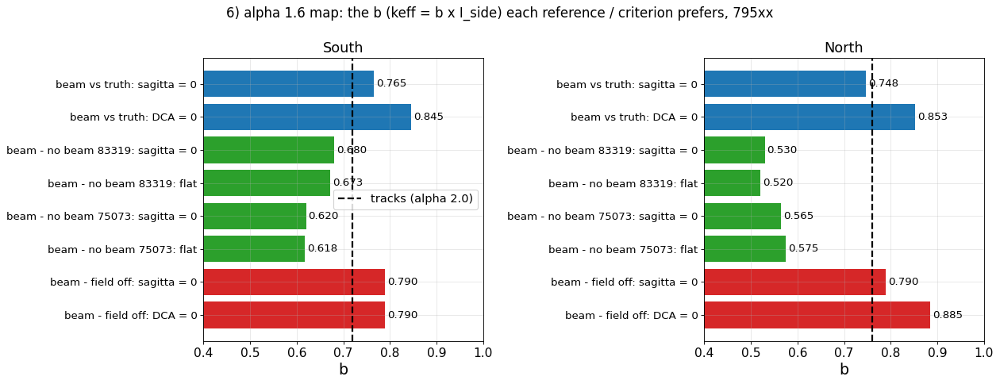

CONFIG  alpha 2.0 map from the big scan (z -40 mm, tilt 0.16/0.85, P/T, IFC automatic), keff = b x I_side, 795xx


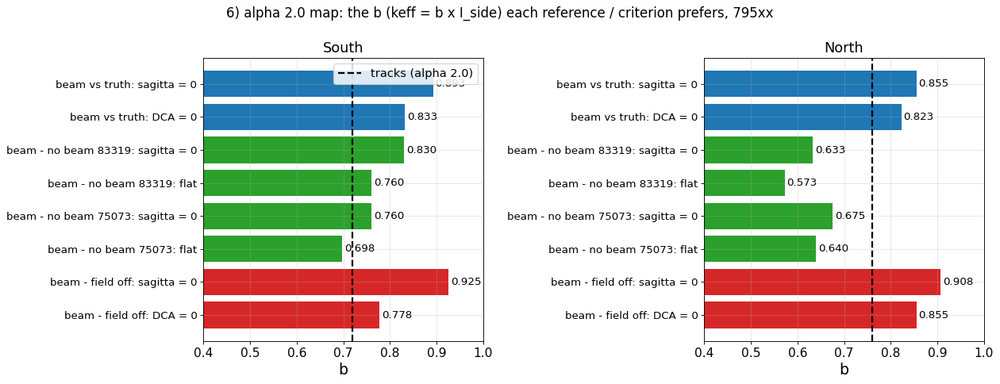

In [14]:
D = bp.data()
def votes(m):
    out = {}
    for s in (0, 1):
        # beam - no beam: flat and sagitta from the scan profiles minus no beam
        for nb in (75073, 83319):
            out[(f'beam - no beam {nb}', 'flat', s)] = D.best(m, runs=bp.LOW, nb=nb, sides=(s,))[0]
            sg = np.array([D.sag(m, bb, runs=bp.LOW, nb=nb, sides=(s,)) for bb in bp.BFINE])
            out[(f'beam - no beam {nb}', 'sagitta = 0', s)] = bp.BFINE[np.nanargmin(np.abs(sg))]
        # beam vs field off (ref 0) / truth (ref 1): absolute criteria on the beam rings themselves
        for ref, name in ((0, 'beam - field off'), (1, 'beam vs truth')):
            sag, dca = [], []
            for bb in bp.BFINE:
                ss, dd = [], []
                for run, blk in D.blocks:
                    if run not in bp.LOW: continue
                    L = D.lin(run, blk, m, s, ref=ref)
                    if L is None: continue
                    P = L[0][0] * bb + L[0][1]; ok = np.isfinite(P)
                    if ok.sum() < 6: continue
                    ss.append(np.polyfit(R[ok], 100 * P[ok] / R[ok], 1)[0] * v.SAG_PER_SLOPE)
                    dd.append(np.polyval(np.polyfit(R[ok], P[ok], 2), 0))
                sag.append(np.nanmean(ss)); dca.append(np.nanmean(dd))
            out[(name, 'sagitta = 0', s)] = bp.BFINE[np.nanargmin(np.abs(sag))]
            out[(name, 'DCA = 0', s)] = bp.BFINE[np.nanargmin(np.abs(dca))]
    return out
for m, lab in ((b.BEST, 'alpha 1.6'), ('prod2p0', 'alpha 2.0')):
    V = votes(m)
    keys = sorted({(k[0], k[1]) for k in V})
    fig, axs = b.pair(f"6) {lab} map: the b (keff = b x I_side) each reference / criterion prefers, 795xx")
    for s in (0, 1):
        y = [V[(k[0], k[1], s)] for k in keys]
        axs[s].barh(range(len(keys)), y, color=['tab:green' if 'no beam' in k[0] else ('tab:red' if 'off' in k[0] else 'tab:blue') for k in keys])
        for i, yy in enumerate(y): axs[s].text(yy + 0.005, i, f"{yy:.3f}", va='center', fontsize=12)
        axs[s].set_yticks(range(len(keys))); axs[s].set_yticklabels([f"{k[0]}: {k[1]}" for k in keys], fontsize=12)
        axs[s].axvline(0.72 if s == 0 else 0.76, color='k', ls='--', label='tracks (alpha 2.0)')
        axs[s].set_xlim(0.4, 1.0); axs[s].set_title(c.SIDES[s]); axs[s].set_xlabel('b')
    axs[0].legend(); fig.tight_layout()
    print(f"CONFIG  {lab} map from the big scan (z -40 mm, tilt 0.16/0.85, P/T, IFC automatic), keff = b x I_side, 795xx")
    show(fig)

### 6a. Take the space charge out completely: no beam vs field off
No beam, so no space charge; only the static correction is applied. The comparison is field on vs field off (no E×B).

**What is plotted.** The sagitta of no beam vs field off against the TPC z shift, for every static variant: nominal,
IFC ±60 V per side, module-frame charge 0 / −360. Then Δφ(R) for each variant.

**Take-away.**
- A sagitta of about −290 µm South and −430 µm North remains with no space charge at all. It doesn't depend on z.
- It responds to the IFC voltage at −3.1 µm per V. So it looks like an E×B-type static field error near the inner
  field cage, and lowering the IFC by about 95 V South and 140 V North in the model would remove it.
- This is exactly the piece the absolute laser fit had absorbed into keff.

CONFIG  no beam (75073 / 83319) and field off (78242), static correction only (keff 0), P/T CM field; variants: IFC +-60 V per side, frame 0 / -360


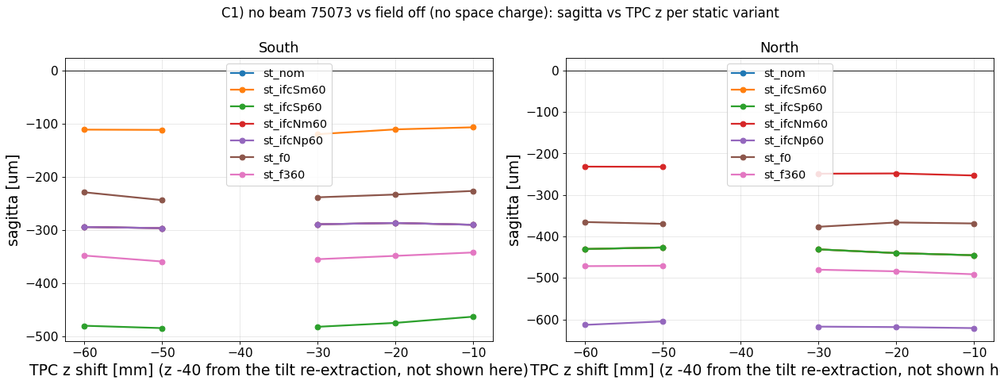

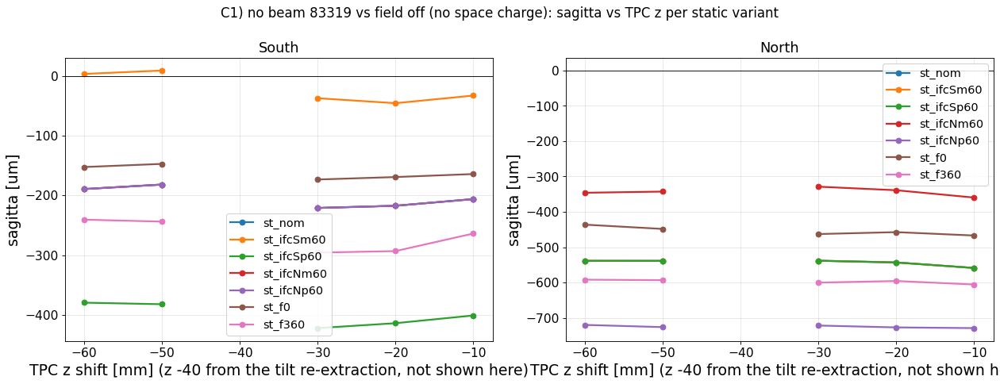

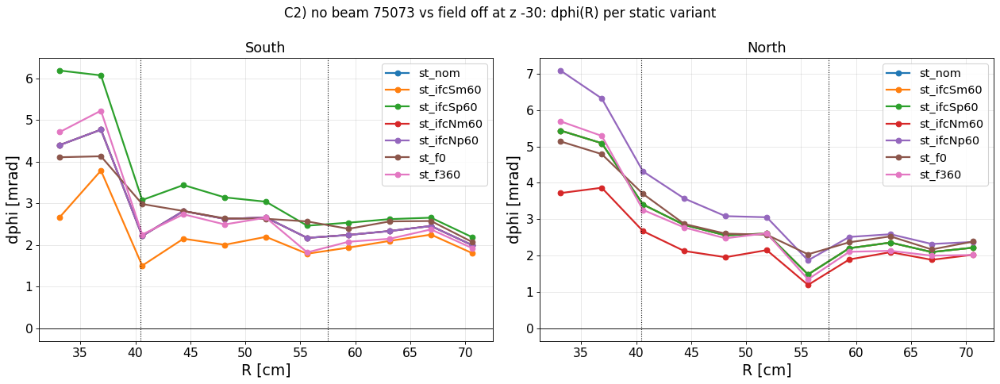

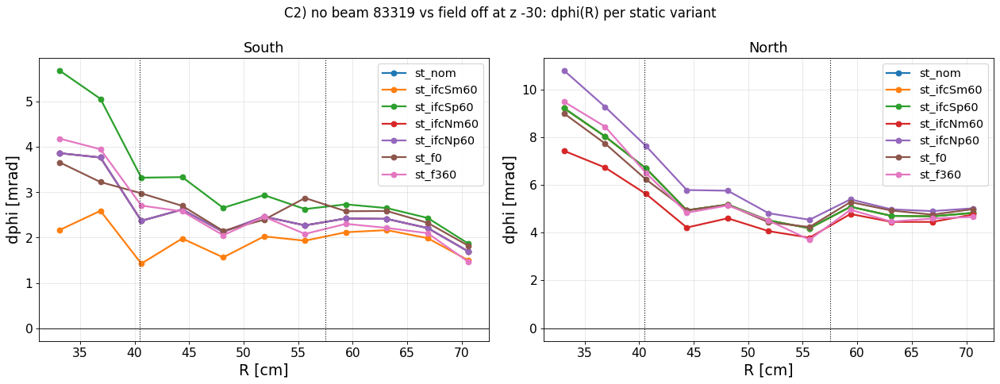

no beam 75073 vs field off (z -30): South: sagitta -289 um, -3.02 um/V -> IFC offset -96 V | North: sagitta -431 um, -3.07 um/V -> IFC offset -140 V
no beam 83319 vs field off (z -30): South: sagitta -221 um, -3.21 um/V -> IFC offset -69 V | North: sagitta -538 um, -3.28 um/V -> IFC offset -164 V


In [15]:
print("CONFIG  no beam (75073 / 83319) and field off (78242), static correction only (keff 0), P/T CM field; variants: IFC +-60 V per side, frame 0 / -360")
show(b.c_static_z(75073), b.c_static_z(83319))
show(b.c_static_prof(75073), b.c_static_prof(83319))
D = bp.data()
def sag_of(key):
    if key not in D.B: return np.nan
    d = 100 * D.B[key][0] / R; ok = np.isfinite(d)
    return np.polyfit(R[ok], d[ok], 1)[0] * v.SAG_PER_SLOPE
for run in (75073, 83319):
    out = []
    for s, (m, p) in ((0, ('st_ifcSm60', 'st_ifcSp60')), (1, ('st_ifcNm60', 'st_ifcNp60'))):
        s0, sm, sp_ = (sag_of((0, run, 0, -30, t, 0.0, s)) for t in ('st_nom', m, p))
        out.append(f"{c.SIDES[s]}: sagitta {s0:+.0f} um, {(sp_-sm)/120:+.2f} um/V -> IFC offset {-s0/((sp_-sm)/120):+.0f} V")
    print(f"no beam {run} vs field off (z -30): " + " | ".join(out))

### 6c. Is a sine left once the space charge is taken out?
**What is plotted.** Δφ vs φ (top of each pair) and dR vs φ (bottom) at the middle ring of each module:
- R1 ≈ 37 cm;
- R2 ≈ 48 cm;
- R3 ≈ 67 cm.

Medians in 10° bins, with a fit a + c·cos φ + s·sin φ per ring (lines). The constant a (a rotation, which is free) is
removed in the plot. The legend gives the first-harmonic amplitude A = √(c² + s²) and its phase.

Comparisons:
- beam − no beam: space charge only, after the correction;
- beam − field off at the space-charge keff;
- no beam − field off: static only, no space charge at all.

A sine that survives in no beam − field off is static: TPC tilt, x/y offset or a field-cage asymmetry. It is not space
charge.

CONFIG  sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        beam - no beam 75073, alpha 1.6 SC keff (795xx)


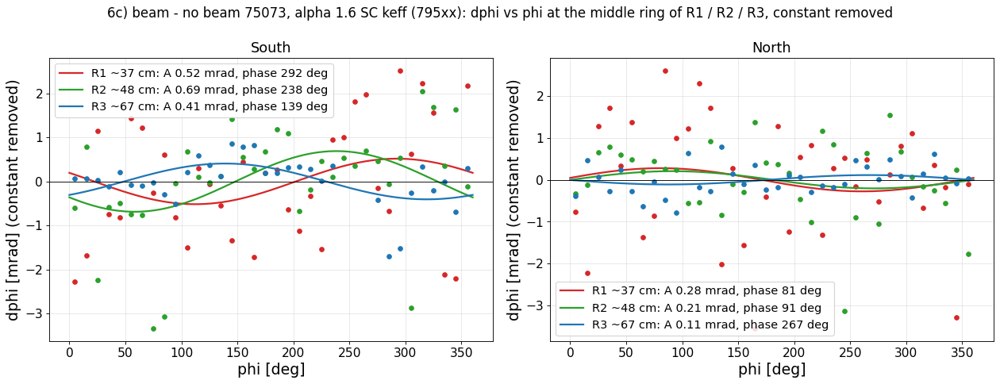

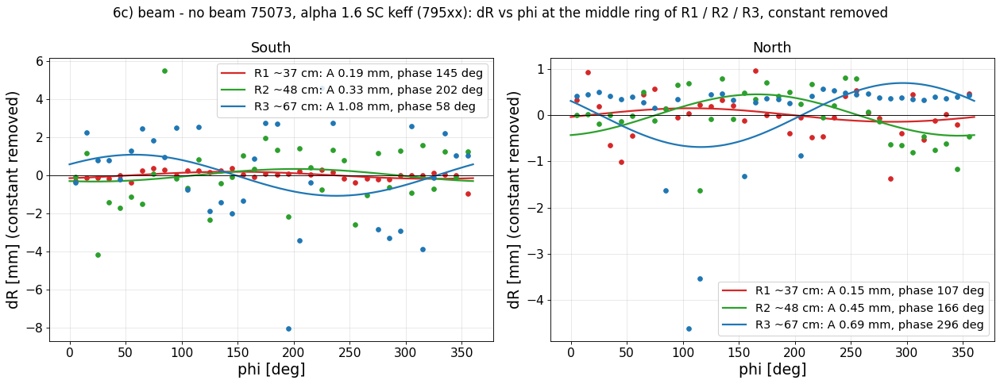

CONFIG  sc16   : alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347); high lumi b 0.685 / 0.652; + static as above
        beam - field off, alpha 1.6 SC keff (795xx)


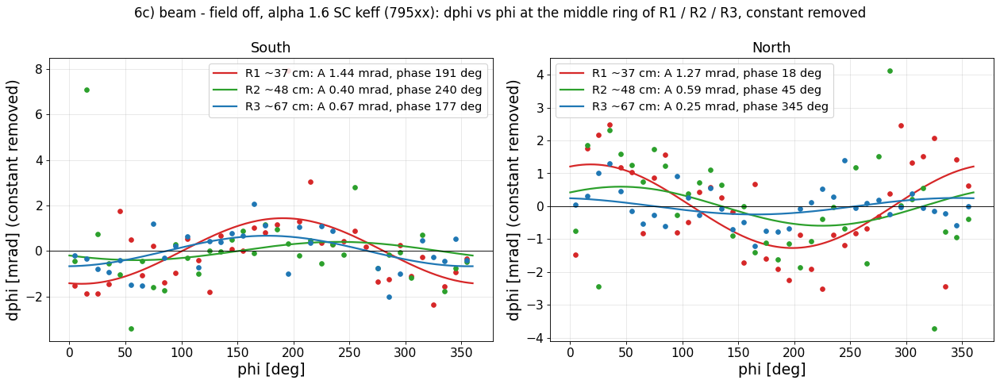

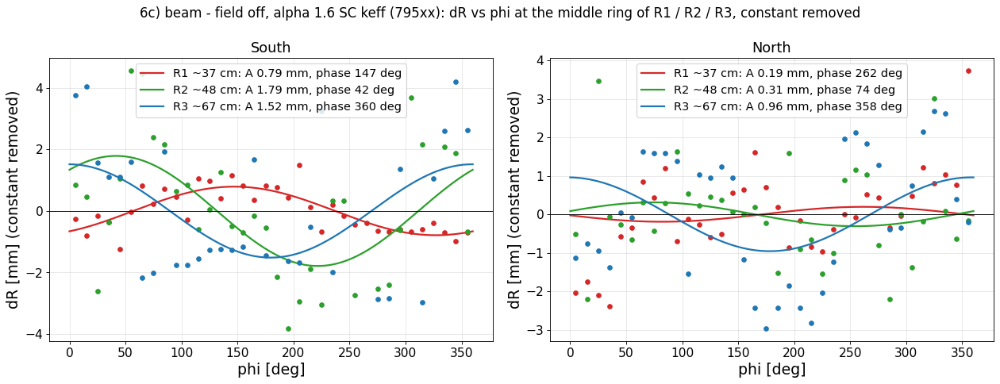

CONFIG  static : static correction only (z -40 mm, tilt 0.16/0.85 mrad, P/T CM field, IFC automatic), keff 0
        no beam 75073 - field off, static only


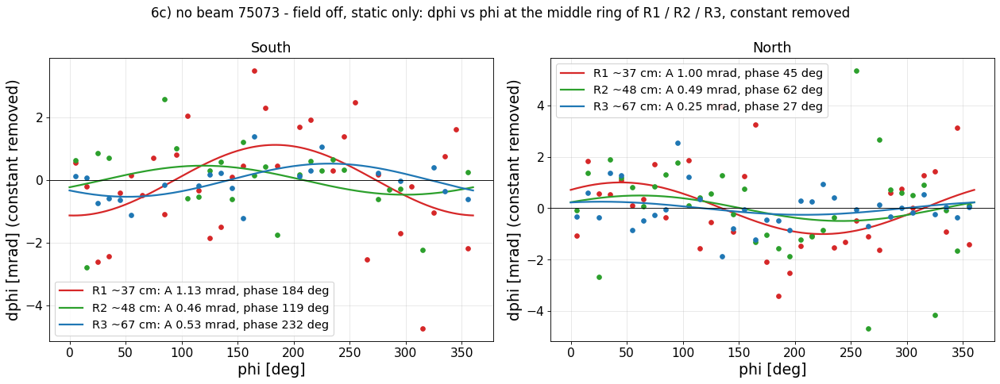

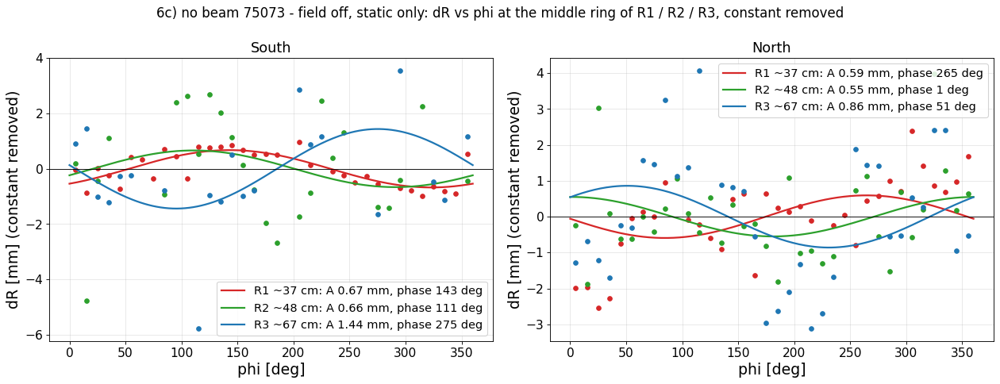

CONFIG  static : static correction only (z -40 mm, tilt 0.16/0.85 mrad, P/T CM field, IFC automatic), keff 0
        no beam 83319 - field off, static only


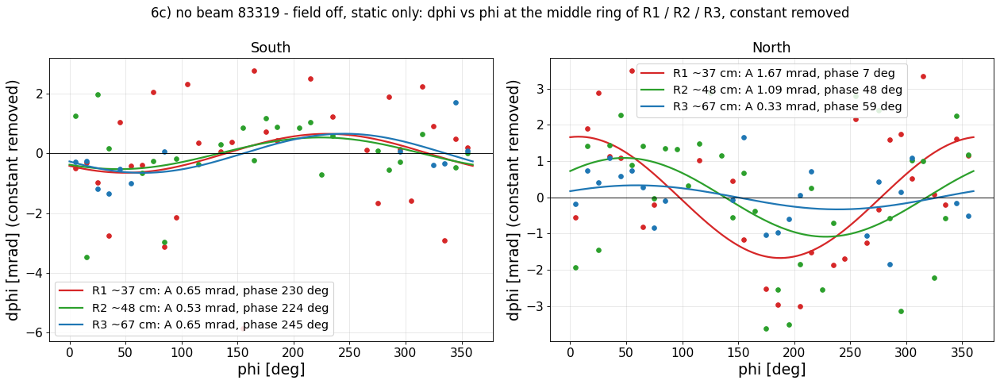

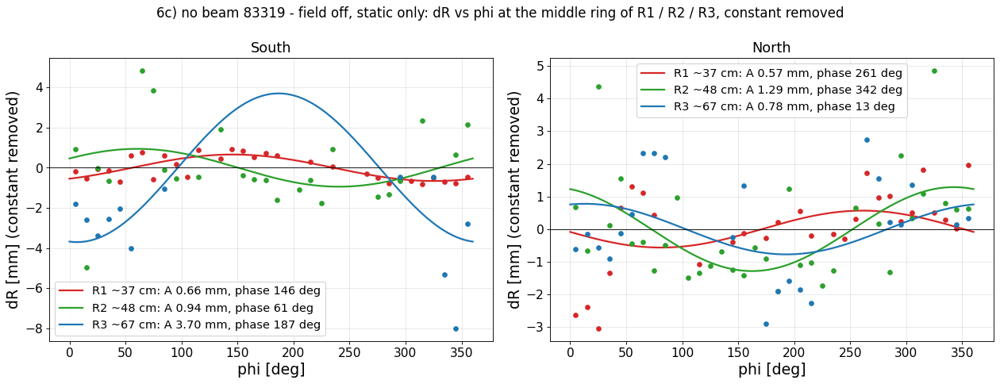

In [16]:
RINGS3 = ((4, 'R1 ~37 cm', 'tab:red'), (7, 'R2 ~48 cm', 'tab:green'), (12, 'R3 ~67 cm', 'tab:blue'))
def harm(ph, y):
    ok = np.isfinite(y)
    A = np.vstack([np.ones(ok.sum()), np.cos(ph[ok]), np.sin(ph[ok])]).T
    return np.linalg.lstsq(A, y[ok], rcond=None)[0]
def sine_plot(name, keys, title, q=5, nphi=36):
    a_all = c.load_many(name, keys)
    edges = np.linspace(0, 2 * np.pi, nphi + 1); pc = 0.5 * (edges[1:] + edges[:-1]); fine = np.linspace(0, 2 * np.pi, 200)
    fig, axs = b.pair(f"6c) {title}: {b.QL[q].split(' [')[0]} vs phi at the middle ring of R1 / R2 / R3, constant removed")
    for s_ in (0, 1):
        a = a_all[a_all[:, 0] == s_]
        j = np.floor((a[:, 1] - 20) / 3.75).astype(int); ph = a[:, 2] % (2 * np.pi)
        for r, lab, col in RINGS3:
            sel = j == r
            y = np.array([np.median(a[sel & (ph >= edges[i]) & (ph < edges[i + 1]), q]) if (sel & (ph >= edges[i]) & (ph < edges[i + 1])).sum() > 2 else np.nan
                          for i in range(nphi)])
            cf = harm(pc, y)
            amp, phase = np.hypot(cf[1], cf[2]), np.degrees(np.arctan2(cf[2], cf[1])) % 360
            axs[s_].plot(np.degrees(pc), y - cf[0], 'o', color=col, ms=5)
            axs[s_].plot(np.degrees(fine), cf[1] * np.cos(fine) + cf[2] * np.sin(fine), '-', color=col,
                         label=f"{lab}: A {amp:.2f} {b.QL[q].split('[')[1][:-1]}, phase {phase:.0f} deg")
        axs[s_].set_title(c.SIDES[s_])
    return b.finish(fig, axs, xl='phi [deg]', yl=b.QL[q] + ' (constant removed)')
CASES = (('NB75_sc16', low, 'beam - no beam 75073, alpha 1.6 SC keff (795xx)', 'sc16'),
         ('OFF_sc16', low, 'beam - field off, alpha 1.6 SC keff (795xx)', 'sc16'),
         ('NBOFF_static', ['75073'], 'no beam 75073 - field off, static only', 'static'),
         ('NBOFF_static', ['83319'], 'no beam 83319 - field off, static only', 'static'))
for name, keys, title, st in CASES:
    cfg(st, extra=title)
    show(sine_plot(name, keys, title, q=5), sine_plot(name, keys, title, q=3))

**The same first harmonic for the scanned TPC tilts.** No beam − field off, static correction only, z −40, 12 sectors
(sector medians, rings in R2). A remaining sine that changes with rot_x / rot_y is a tilt; one that doesn't is
something else (an x/y offset or a field-cage asymmetry).

CONFIG  no beam 75073 vs field off, static correction only, z -40 mm, TPC rotation varied (rx, ry in mrad)


/tmp/ipykernel_59828/1830903569.py:12: RuntimeWarning: Mean of empty slice
  PS = np.nanmean(T['PS'][sel], axis=0)          # [12 sectors, 11 rings]


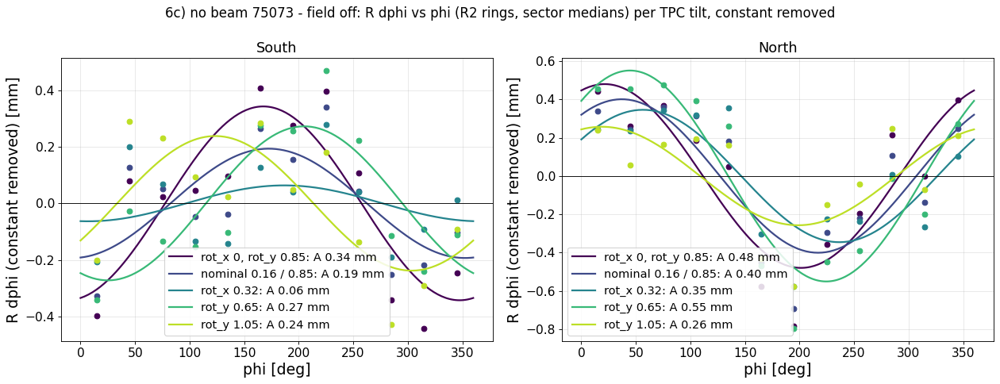

CONFIG  no beam 83319 vs field off, static correction only, z -40 mm, TPC rotation varied (rx, ry in mrad)


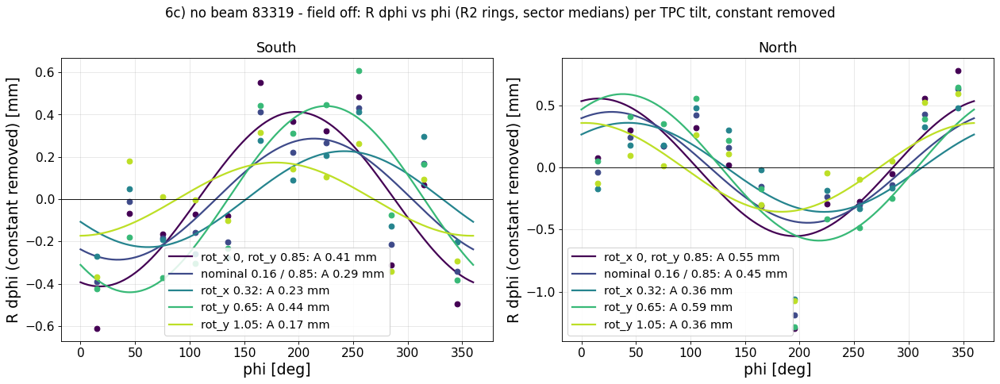

In [17]:
T = b._tilt()
geoms = [('rx0_ry0p85', 'rot_x 0, rot_y 0.85'), ('rx0p16_ry0p85', 'nominal 0.16 / 0.85'), ('rx0p32_ry0p85', 'rot_x 0.32'),
         ('rx0p16_ry0p65', 'rot_y 0.65'), ('rx0p16_ry1p05', 'rot_y 1.05')]
phs = np.radians(np.arange(12) * 30 + 15); fine = np.linspace(0, 2 * np.pi, 200)
for run in (75073, 83319):
    print(f"CONFIG  no beam {run} vs field off, static correction only, z -40 mm, TPC rotation varied (rx, ry in mrad)")
    fig, axs = b.pair(f"6c) no beam {run} - field off: R dphi vs phi (R2 rings, sector medians) per TPC tilt, constant removed")
    for s_ in (0, 1):
        for (g, lab), col in zip(geoms, plt.cm.viridis(np.linspace(0, 0.9, len(geoms)))):
            sel = (T['ref'] == 0) & (T['run'] == run) & (T['geom'] == g) & (T['tag'] == 'st_nom') & (T['side'] == s_)
            if not sel.any(): continue
            PS = np.nanmean(T['PS'][sel], axis=0)          # [12 sectors, 11 rings]
            y = np.nanmean(PS[:, 3:7], axis=1)             # rings 40-55 cm (R2)
            cf = harm(phs, y)
            axs[s_].plot(np.degrees(phs), y - cf[0], 'o', color=col)
            axs[s_].plot(np.degrees(fine), cf[1] * np.cos(fine) + cf[2] * np.sin(fine), '-', color=col,
                         label=f"{lab}: A {np.hypot(cf[1], cf[2]):.2f} mm")
        axs[s_].set_title(c.SIDES[s_])
    show(b.finish(fig, axs, xl='phi [deg]', yl='R dphi (constant removed) [mm]'))

### 6b. TPC tilt
**What is plotted.** The first harmonic of RΔφ(φ) (no beam vs field off) for five TPC rotations. A tilt of the TPC in
the magnetic field makes a sin φ / cos φ pattern.

**Take-away.** The smallest harmonic is near rot_x ≈ 0.3 mrad (currently 0.16).

CONFIG  no beam vs field off, static correction only, z -40 mm, TPC rotation (rx, ry) varied


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/bsnb.py:357: RuntimeWarning: Mean of empty slice
  PS = np.nanmean(T['PS'][sel], axis=0)          # [12, 11]
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/bsnb.py:357: RuntimeWarning: Mean of empty slice
  PS = np.nanmean(T['PS'][sel], axis=0)          # [12, 11]


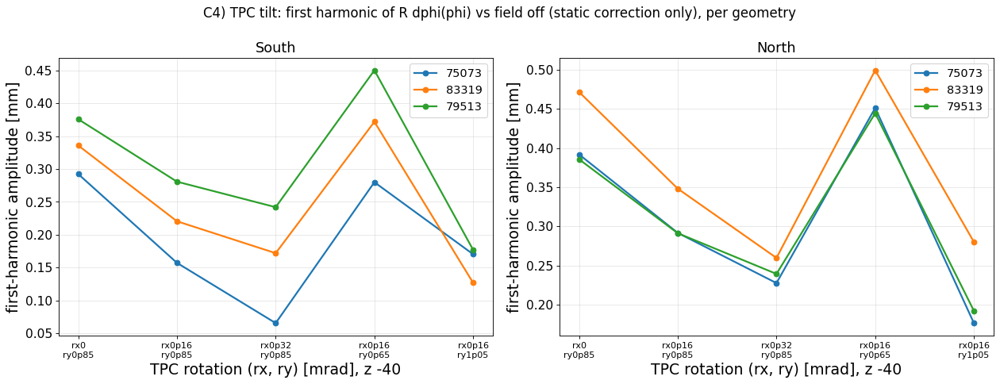

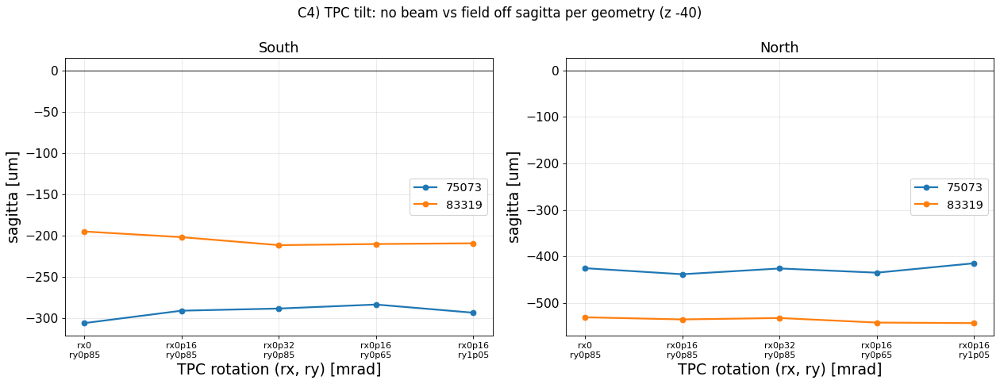

In [18]:
print("CONFIG  no beam vs field off, static correction only, z -40 mm, TPC rotation (rx, ry) varied")
show(b.c_tilt(), b.c_tilt_sag())

## 7. Summary and next steps
**Space charge (beam − no beam):**
- Map: α 1.6. The inner-kink and outer-edge details matter little.
- keff = b × I_side with b ≈ 0.60, linear in the GEM current up to 6.6 µA. North is about 7 % lower.

**Static:**
- With no beam, a sagitta of −290 / −430 µm (South / North) remains vs field off, independent of z.
- It is IFC-like: −3.1 µm/V, so about −95 V South and −140 V North in the model.
- That piece had been absorbed into keff by the absolute fit, which is why keff came out too high (0.84). Tracks sit in
  between (0.72–0.76).

**Next:**
1. α 1.6 track keff scan (running): charge balance, rDCA.
2. A fine IFC / OFC and tilt scan with beam.
3. Module gains vs no beam with α 1.6.
4. Production settings: α 1.6, keff = b × I_side, and the corrected static model.

Backuo

## 3. Two ways to measure the residual
| | **A: vs CM truth** | **B: cluster to cluster vs another run** |
|---|---|---|
| reference | stripe positions | the same stripes measured in another run |
| matching | nearest stripe to the corrected cluster | mutual nearest clusters; "robust" removes a radial offset per ring first (field off has mm offsets) |
| what cancels | nothing | everything common to both runs |
| examples | beam vs truth | **beam − no beam** (both field on): static distortions, stripe pattern and field off cancel, so only space charge is left. **beam − field off**: no E×B in the reference. **no beam − field off**: only the static field-on distortion, no space charge. |
| caveat | stripe pattern errors; the no-beam truth matching picks wrong stripes | matching margin; run-to-run changes (IFC, the North change before 83319) |

**What is plotted below** (matching QA): how many clusters are matched per CM stripe row, and how well separated the
matches are.


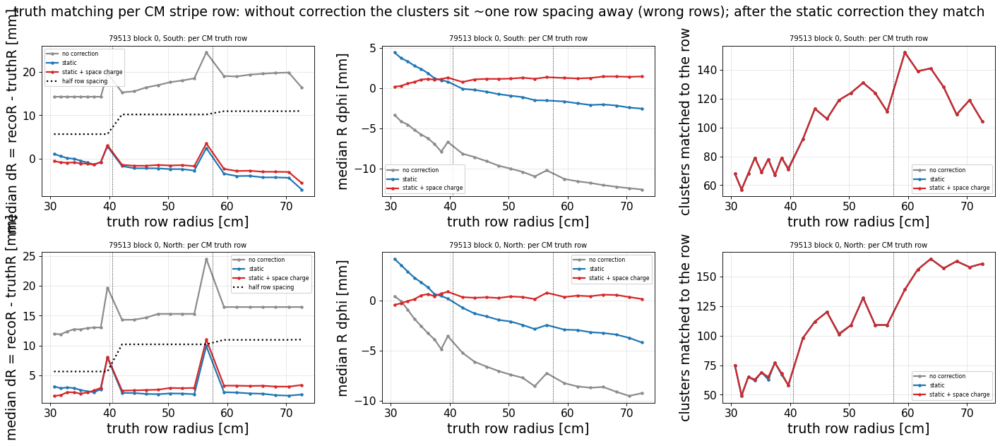

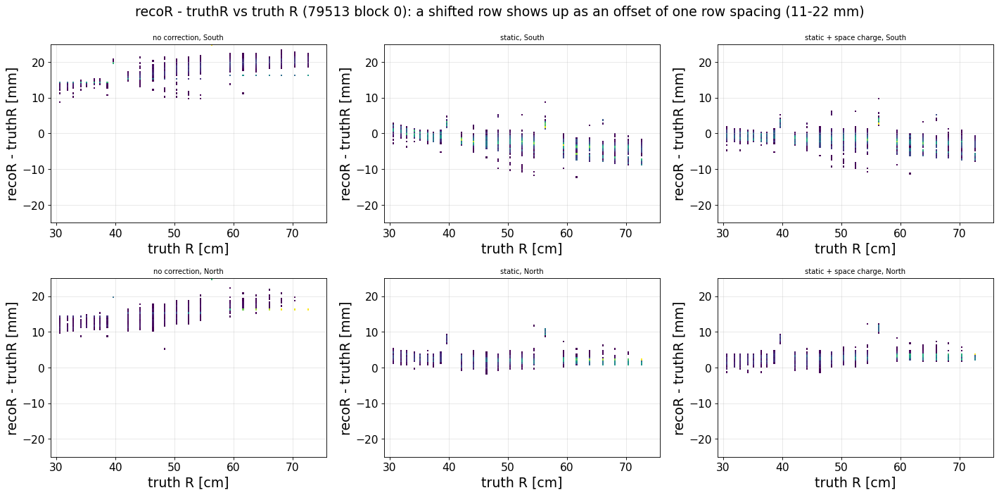

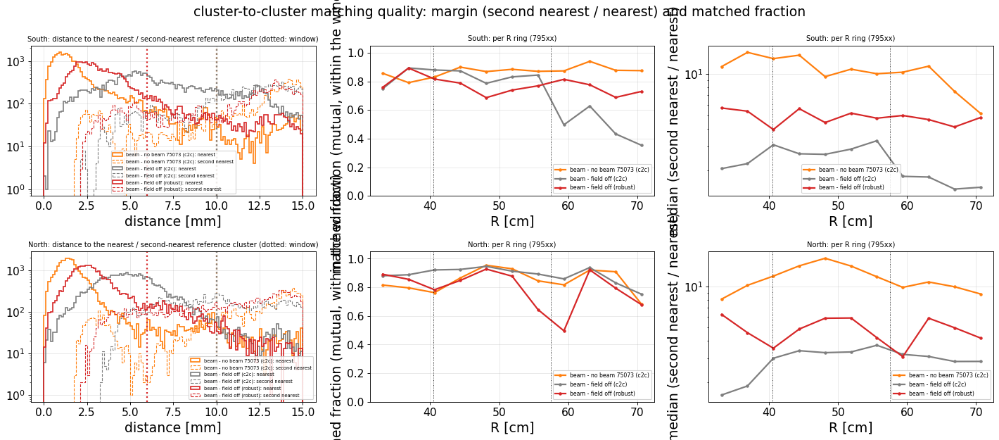

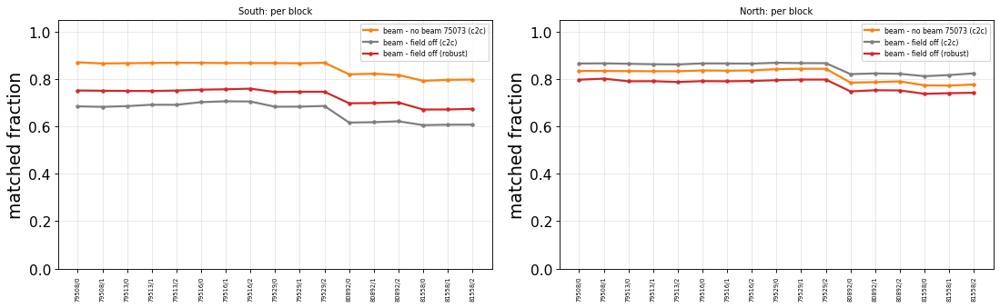

In [19]:
import matchplots as mp
ft = mp.sec_truth(); show(*ft[:2])
fc = mp.sec_c2c(); show(*fc[:2])

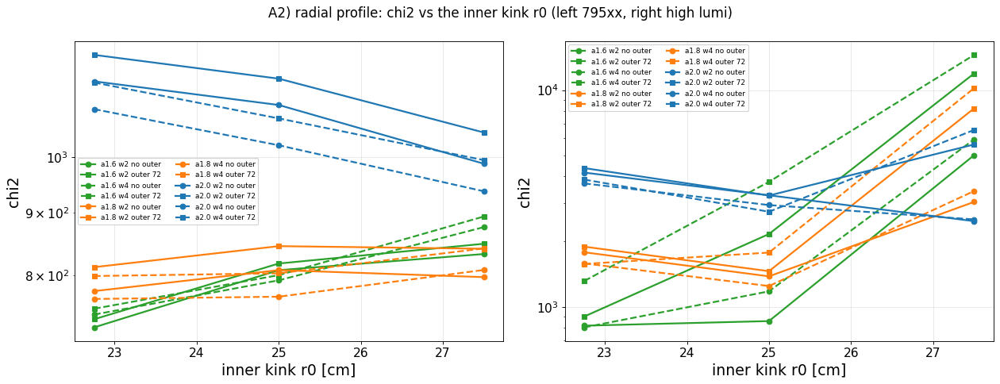

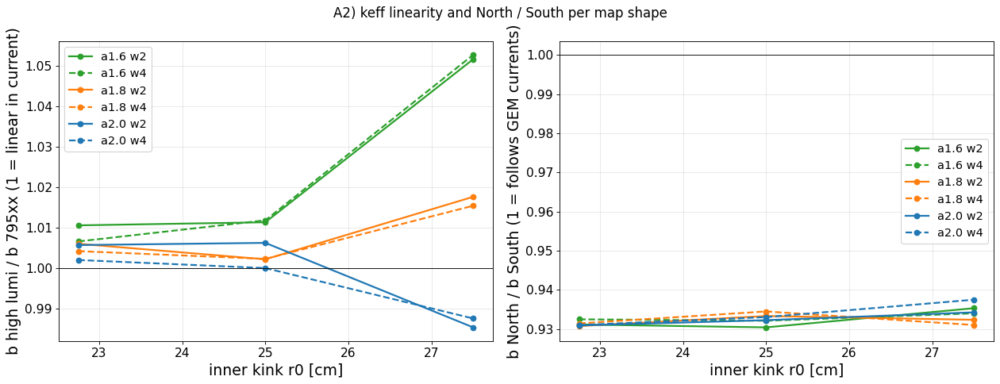

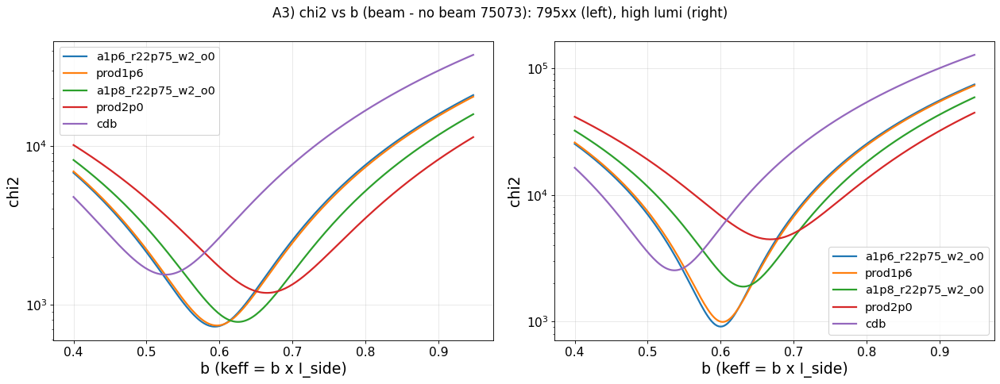

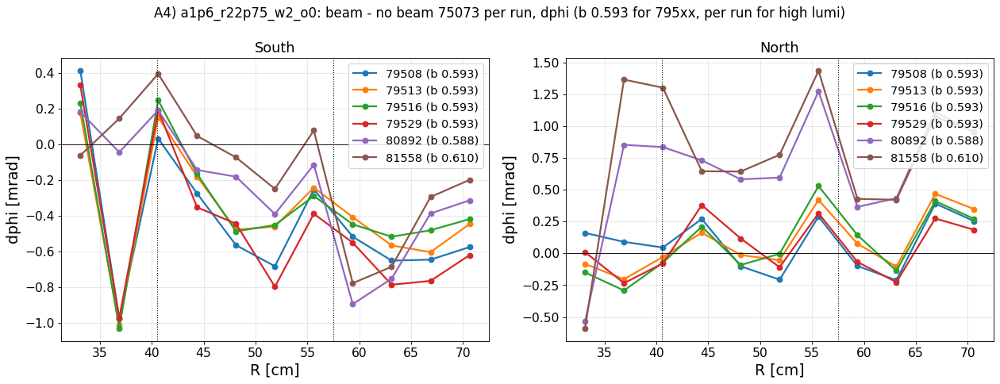

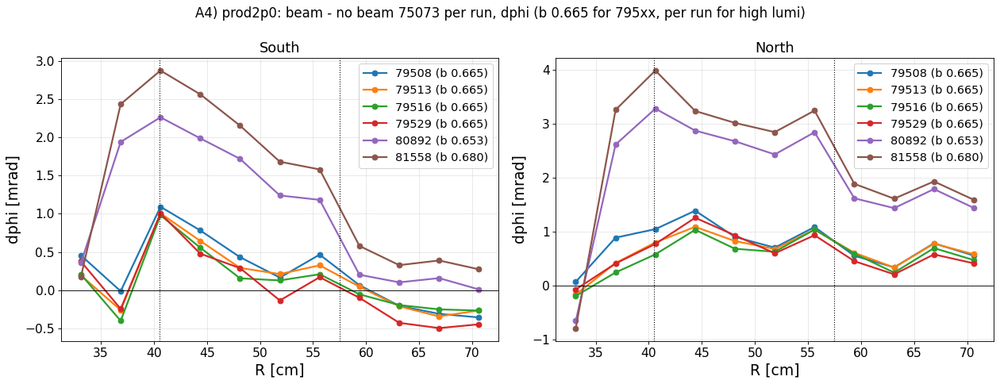

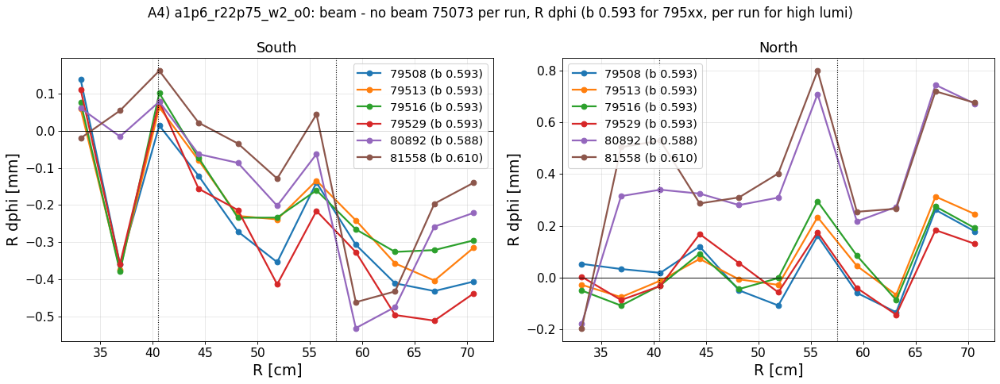

In [20]:
show(*b.a_params())
show(b.a_chi2_curves())
show(b.a_profiles(b.BEST, q=5), b.a_profiles('prod2p0', q=5), b.a_profiles(b.BEST, q=4))

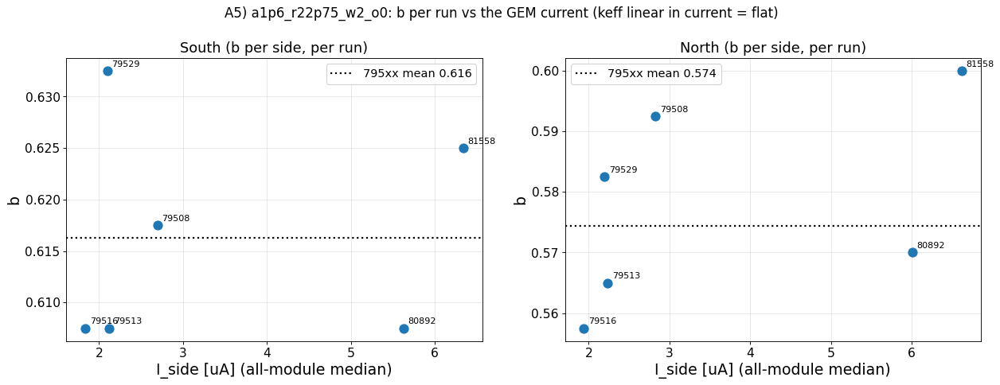

In [21]:
show(b.a_keff_runs())